In [1]:
import os
import urllib.request
import gzip
import shutil
import pandas as pd
import re
import fasttext
import gensim
from gensim.models import Word2Vec, FastText
import random
import spacy
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import calamancy
import matplotlib.pyplot as plt

In [ ]:
# df = pd.read_csv('tl_corpus_genre_agg.csv')
df = pd.read_csv('tl_joined_tokens_agg.csv')

In [16]:
df

,sentence_id,filename,genre1,genre2,genre_group,token,processed
0,0,2024PANANAGINIP SA TAG-ARAW.txt,tula,tula,traditional,Gusto ko nang lumabas Dahil gusto ko na tumakb...,gusto ko nang lumabas dahil gusto ko na tumakb...
1,1,2024PANANAGINIP SA TAG-ARAW.txt,tula,tula,traditional,Paano ang social distancing sa munti nilang ba...,paano ang social distancing sa munti nilang ba...
2,2,2024PANANAGINIP SA TAG-ARAW.txt,tula,tula,traditional,Gusto ko nang lumabas Bago pa naman ang sapato...,gusto ko nang lumabas bago pa naman ang sapato...
3,3,2024PANANAGINIP SA TAG-ARAW.txt,tula,tula,traditional,May espesyal na ayuda ba sa mga natanggalan ng...,may espesyal na ayuda ba sa mga natanggalan ng...
4,4,2024PANANAGINIP SA TAG-ARAW.txt,tula,tula,traditional,Gusto ko nang lumabas Sa bukid magpalipad ng s...,gusto ko nang lumabas sa bukid magpalipad ng s...
...,...,...,...,...,...,...,...
28730,31736,Karapat-Dapat.txt,nonfiction,nonfiction,creative nonfiction,Dapat kang saklolohan kung ikaw ay nasaktan na...,dapat kang saklolohan kung ikaw ay nasaktan na...
28731,31737,Karapat-Dapat.txt,nonfiction,nonfiction,creative nonfiction,May karapatan kang makatanggap ng tulong na le...,may karapatan kang makatanggap ng tulong na le...
28732,31738,Karapat-Dapat.txt,nonfiction,nonfiction,creative nonfiction,Kung ang mga batas sa iyong bansa ay nagkakalo...,kung ang mga batas sa iyong bansa ay nagkakalo...
28733,31739,Karapat-Dapat.txt,nonfiction,nonfiction,creative nonfiction,Karapatan mong alamin ang iyong mga karapatan ...,karapatan mong alamin ang iyong mga karapatan ...


## Change genre group of parables to fiction

In [17]:
df['token'] = df['token'].str.replace("-", "_")
df['processed'] = df['processed'].str.replace("-", "_")

In [18]:
df['genre_group'].value_counts()

genre_group
fiction                17013
traditional             8112
creative nonfiction     3610
Name: count, dtype: int64

In [19]:
fiction_df = df[df['genre_group'] == 'fiction']
traditional_df = df[df['genre_group'] == 'traditional']
nonfiction_df = df[df['genre_group'] == 'creative nonfiction']

### Save each df to its own text file (DO NOT RUN NOW)

In [20]:
filenames = ['fiction_agg.txt', 'traditional_agg.txt', 'nonfiction_agg.txt']
groups = [fiction_df, traditional_df , nonfiction_df]
folder = './txt-files'

for filename, group, in zip(filenames, groups):
    file_route = folder + '/' + filename
    with open(file_route, 'w', encoding='utf-8') as f:
        for row in group['processed']:
            f.write(row + '\n')
    print(f"✅ Corpus saved to {filename} with {len(group)} sentences.")

✅ Corpus saved to fiction_agg.txt with 17013 sentences.
✅ Corpus saved to traditional_agg.txt with 8112 sentences.
✅ Corpus saved to nonfiction_agg.txt with 3610 sentences.


In [21]:
wholefile = [df]
wholefilename = ['all_corpus_agg.txt']
folder = './txt-files'
for filename, df in zip(wholefilename, wholefile):
    file_route = folder + '/' + filename
    with open(file_route, 'w', encoding='utf-8') as f:
        for row in df['processed']:
            f.write(row + '\n')
    print(f"✅ Corpus saved to {filename} with {len(df)} sentences.")

✅ Corpus saved to all_corpus_agg.txt with 28735 sentences.


## Run 1st genre grp model

In [186]:
os.environ["PYTHONHASHSEED"] = "0"
random.seed(40)
np.random.seed(40)

In [187]:
import unicodedata

def cleanTxt(filename):
    with open(f'./txt-files/{filename}', 'r', encoding='utf-8') as f:
        text = f.read()
    
    cleanText = unicodedata.normalize('NFKC', text)
    with open(f"./txt-files/clean_{filename}", "w", encoding="utf-8") as f:
        f.write(cleanText)

In [188]:
cleanTxt('fiction_agg.txt')
cleanTxt('traditional_agg.txt')
cleanTxt('nonfiction_agg.txt')

cleanTxt('all_corpus_agg.txt')

### Define functions

In [ ]:
class MyCorpus:
    """An iterator that yields sentences from a text file."""
    def __init__(self, filename):
        self.filename = filename

    def __iter__(self):
        with open(self.filename, 'r', encoding='utf-8') as f:
            for line in f:
                # Basic tokenization: split by whitespace
                yield line.lower().strip().split()

# Create an instance of your corpus iterator

def trainWord2Vec(folder, file, model, dim, ws, epoch, minCount):
    
    fileDir = folder + '/' + file
    paragraphs = MyCorpus(fileDir)
    nlp = Word2Vec(
        paragraphs,
        vector_size=dim,
        window=ws,
        min_count=minCount,
        sg=model,  # 0:cbow, 1:skip-gram
        workers=4,
        epochs=epoch
    )
    return nlp

def saveW2VModel(folder, file, nlp):
    fileStr = file[:-4]
    MODEL_FILE = fileStr + '_model_w2v'
    nlp.save(folder + '/' + MODEL_FILE + '.bin')
    print(f"✅ Model saved to {MODEL_FILE}.bin")


In [ ]:
model_all = trainWord2Vec('./txt-files', 'clean_all_corpus_agg.txt', 1, 20, 3, 100, 2)
model_fiction = trainWord2Vec('./txt-files', 'clean_fiction_agg.txt', 1, 20, 3, 100, 2)
model_traditional = trainWord2Vec('./txt-files', 'clean_traditional_agg.txt', 1, 20, 3, 100, 2)
model_nonfiction = trainWord2Vec('./txt-files', 'clean_nonfiction_agg.txt', 1, 20, 3, 100, 2)

In [191]:
len(model_fiction.wv.index_to_key)

8208

In [192]:
model_all.wv.most_similar('lalaki', topn=10)

[('babae', 0.9058308601379395),
 ('masunurin', 0.8726363182067871),
 ('kalugud_lugod', 0.8574947118759155),
 ('magalang', 0.8435293436050415),
 ('batang', 0.8423873782157898),
 ('judio', 0.8313931226730347),
 ('matapang', 0.8219071626663208),
 ('mabait', 0.8175746202468872),
 ('masayahin', 0.8175085783004761),
 ('obed', 0.8038554191589355)]

In [193]:
len(model_traditional.wv.index_to_key)

5125

In [194]:
len(model_nonfiction.wv.index_to_key)

3332

## Model 2

In [195]:
model_all_50 = trainWord2Vec('./txt-files', 'clean_all_corpus_agg.txt', 1, 50, 5, 100, 2)

model_fiction_50 = trainWord2Vec('./txt-files', 'clean_fiction_agg.txt', 1, 50, 5, 100, 2)
model_traditional_50 = trainWord2Vec('./txt-files', 'clean_traditional_agg.txt', 1, 50, 5, 100, 2)
model_nonfiction_50 = trainWord2Vec('./txt-files', 'clean_nonfiction_agg.txt', 1, 50, 5, 100, 2)

## Model 3

In [196]:
model_all_100 = trainWord2Vec('./txt-files', 'clean_all_corpus_agg.txt', 1, 100, 10, 100, 2)

model_fiction_100 = trainWord2Vec('./txt-files', 'clean_fiction_agg.txt', 1, 100, 10, 100, 2)
model_traditional_100 = trainWord2Vec('./txt-files', 'clean_traditional_agg.txt', 1, 100, 10, 100, 2)
model_nonfiction_100 = trainWord2Vec('./txt-files', 'clean_nonfiction_agg.txt', 1, 100, 10, 100, 2)


# View Parts of Speech

In [3]:
# load models

model_fiction = Word2Vec.load('./txt-files/clean_fiction_agg_model_w2v.bin')
model_traditional = Word2Vec.load('./txt-files/clean_traditional_agg_model_w2v.bin')
model_nonfiction = Word2Vec.load('./txt-files/clean_nonfiction_agg_model_w2v.bin')

model_all = Word2Vec.load('./txt-files/clean_all_corpus_agg_model_w2v.bin')

model_fiction_50 = Word2Vec.load('./txt-files/50_clean_fiction_agg_model_w2v.bin')
model_traditional_50 = Word2Vec.load('./txt-files/50_clean_traditional_agg_model_w2v.bin')
model_nonfiction_50 = Word2Vec.load('./txt-files/50_clean_nonfiction_agg_model_w2v.bin')
model_all_50 = Word2Vec.load('./txt-files/50_clean_all_corpus_agg_model_w2v.bin')

model_fiction_100 = Word2Vec.load('./txt-files/100_clean_fiction_agg_model_w2v.bin')
model_traditional_100 = Word2Vec.load('./txt-files/100_clean_traditional_agg_model_w2v.bin')
model_nonfiction_100 = Word2Vec.load('./txt-files/100_clean_nonfiction_agg_model_w2v.bin')
model_all_100 = Word2Vec.load('./txt-files/100_clean_all_corpus_agg_model_w2v.bin')

In [ ]:
# load POS reference

POS_ref = pd.read_csv('genrePOSv2-updated.csv')
POS_ref = POS_ref[['token_low', 'pos']]
POS_ref['token_lower'] = POS_ref['token_low'].str.replace("-", "_")
POS_ref

,token_low,pos,token_lower
0,a,X,a
1,aa,X,aa
2,aabisuhan,VERB,aabisuhan
3,aabot,VERB,aabot
4,aabutan,VERB,aabutan
...,...,...,...
27165,zoo,NOUN,zoo
27166,zoom-zoom,NOUN,zoom_zoom
27167,zoop,NOUN,zoop
27168,zorra,NOUN,zorra


In [ ]:
annotations_df = pd.read_csv('genre-pos-fixed-agg.csv')
annotations_df['token_lower'] = annotations_df['token'].str.lower()
annotations_df['token_lower'] = annotations_df['token_lower'].str.replace("-", "_")

fiction = annotations_df[annotations_df['genre_group'] == 'fiction']
traditional = annotations_df[annotations_df['genre_group'] == 'traditional']
nonfiction = annotations_df[annotations_df['genre_group'] == 'creative nonfiction']

# {word: model_fiction.wv.get_vecattr(word, "count") for word in model_fiction.wv.index_to_key}

def cleanPOSDF(df):
    df = df[df['token_lower'] != '-'] 
    # remove rows with hyphen token
    df = df.replace(r"^\s*$", np.nan, regex=True).dropna(subset=["token_lower"])
    # remove rows with space or nan
    return df

def getTopPOS(df, rows=35):
    df = cleanPOSDF(df)
    res_df = pd.DataFrame()
    res_df['noun'] = df[df['pos'] == 'NOUN']['token_lower'].value_counts()[:rows].index.to_list()
    res_df['verb'] = df[df['pos'] == 'VERB']['token_lower'].value_counts()[:rows].index.to_list()
    res_df['pron'] = df[df['pos'] == 'PRON']['token_lower'].value_counts()[:rows].index.to_list()
    res_df['adj'] = df[df['pos'] == 'ADJ']['token_lower'].value_counts()[:rows].index.to_list()
    res_df['adv'] = df[df['pos'] == 'ADV']['token_lower'].value_counts()[:rows].index.to_list()
    res_df['propn'] = df[df['pos'] == 'PROPN']['token_lower'].value_counts()[:rows].index.to_list()

    return res_df

In [ ]:
def show_absolute_value(pct):
    total = sum(counts)
    val = int(round(pct * total / 100.0))
    return f'{val}'
    
def make_autopct(values):
    def my_autopct(pct):
        total = sum(values)
        # Calculate the absolute value using the percentage
        val = int(round(pct * total / 100.0))
        # Return a string with both percentage and absolute value
        return f'{pct:.1f}%\n({val:d})'
    return my_autopct
    
def plot_pie(df):
    select_POS = ['NOUN', 'VERB', 'PRON', 'ADJ', 'ADV', 'PROPN']

    filtered_df = df.loc[df['pos'].isin(select_POS), 'pos'].value_counts()
    
    plt.figure(figsize=(6, 6))
    plt.pie(filtered_df, labels=filtered_df.index, autopct=make_autopct(filtered_df), startangle=140)
    plt.title('Counts of Parts of Speech')
    plt.show()

In [7]:
fiction_voc = model_fiction_100.wv.index_to_key[:310]

In [8]:
traditional_voc = model_traditional_100.wv.index_to_key[:310]

In [9]:
nonfiction_voc = model_nonfiction_100.wv.index_to_key[:310]

## Get most frequent words in vocabulary for thematic grouping

In [10]:
fiction_dict = {word: model_fiction_100.wv.get_vecattr(word, "count") for word in model_fiction_100.wv.index_to_key}
traditional_dict = {word: model_traditional_100.wv.get_vecattr(word, "count") for word in model_traditional_100.wv.index_to_key}
nonfiction_dict = {word: model_nonfiction_100.wv.get_vecattr(word, "count") for word in model_nonfiction_100.wv.index_to_key}

In [11]:
df_voc_fiction = pd.DataFrame(fiction_dict.items(), columns=['token_lower', 'count'])
df_voc_traditional = pd.DataFrame(traditional_dict.items(), columns=['token_lower', 'count'])
df_voc_nonfiction = pd.DataFrame(nonfiction_dict.items(), columns=['token_lower', 'count'])

### List gendered words

In [12]:
### INITIALIZE VARIABLES ###

# Filipino gendered seed words

fil_directly_male = ['lalaki', 'lalaking', 'lalake', 'kalalakihan', 'lalakeng', 
                 'pagkalalaki', 'panlalaki', 'pagkalalake', 'kalalakihang', 
                 'panlalaking', 'pangkalalakihan',
                 'kalalaki', 'kalalaking'
                    ]
fil_directly_female = ['babae', 'babaeng', 'kababaihan', 'pagkababae', 'babaing', 
                   'kababaihang', 'pambabae', 'pambabaeng', 'makababae',
                      'kababae', 'kababaeng'
                      ]

fil_male_marked = ['ama', 'bana', 'bayaw', 'binata', 'binatang', 'binatilyo', 'biyudo', 'bulugan', 'diko', 'duke', 'emperador', 
               'G.', 'ginoo', 'hari', 'ingkong', 'konde', 'kumpadre', 'kumpare', 'kuya', 'kuyang', 'lakan', 'amang',
               'lakandiwa', 'lolo', 'mayordomo', 'monghe', 'padre', 'pare', 'pari', 'patriyarka', 'prinsipe', 'sangko',
               'sireno', 'tandang', 'tatay', 'tinali', 'tito', 'tiyo', 'tiyuhin', 'tay', 'itay', 'katipunero',
               'maghari', 'prinsipeng', 'sultan', 'manong', 'kapitan', 'kapitang',
                  'maestro', 'pastol', 'kartero', 'karterong', 'kutsero', 'kutserong', 'ninong',
                  'tinyente', 'tinyenteng', 'pinakahari', 'prinsipado', 'prinsiping', 'prinsipi', 'haring',
                   'raha', 'lakandula', 'ginoong', 'datu', 'maestrong', 'papa','mestiso'
                   ]

fil_female_marked = ['ate', 'babaylan', 'Bb.', 'binibini', 'binibining', 'biyuda', 'dalaginding', 'dalagita', 'ditse', 'dukesa', 'dumalaga',
                 'emperatris', 'ginang', 'Gng.', 'hipag', 'impo', 'ina', 'inang', 'inahin', 'kondesa', 'kumare', 'lakambini', 'dalaga',
                 'lola', 'madrasta', 'madre', 'mare', 'matriyarka', 'nanay', 'prinsesa', 'reyna', 'sanse', 'sirena', 'dalagang',
                 'tita', 'tiya', 'tiyahin', 'nay', 'inay', 'prinsesang', 'sultana', 'manang', 'maglola', 'kapitana', 'kapitanang',
                    'maybahay', 'katipunera', 'mongha', 'lolay', 'ninang',
                    'inpanta', 'diwata', 'diwatang', 'engkantada', 'engkantadang', 'rane',
                     'mama', 'maestra', 'maestrona', 'mestisa'
                    ]

fil_male = fil_directly_male + fil_male_marked
fil_female = fil_directly_female + fil_female_marked

gender_marked = fil_male+ fil_female

In [13]:
POS_selection = ['NOUN', 'VERB', 'ADJ', 'ADV', 'PROPN']
POS_ref_select = POS_ref[POS_ref['pos'].isin(POS_selection)]
word_pos_lookup = (
    POS_ref_select
    .groupby('token_lower')['pos']
    .apply(lambda x: ', '.join(x.drop_duplicates()))
    .to_dict()
)
qualified_words = list(POS_ref_select['token_lower'])

df_voc_fiction_filt = df_voc_fiction[df_voc_fiction['token_lower'].isin(qualified_words)]
df_voc_traditional_filt = df_voc_traditional[df_voc_traditional['token_lower'].isin(qualified_words)]
df_voc_nonfiction_filt = df_voc_nonfiction[df_voc_nonfiction['token_lower'].isin(qualified_words)]

df_voc_fiction_filt = df_voc_fiction_filt[~df_voc_fiction_filt['token_lower'].isin(gender_marked)]
df_voc_traditional_filt = df_voc_traditional_filt[~df_voc_traditional_filt['token_lower'].isin(gender_marked)]
df_voc_nonfiction_filt = df_voc_nonfiction_filt[~df_voc_nonfiction_filt['token_lower'].isin(gender_marked)]

df_voc_fiction_filt['pos'] = (
    df_voc_fiction_filt['token_lower'].map(word_pos_lookup)
)

df_voc_traditional_filt['pos'] = (
    df_voc_traditional_filt['token_lower'].map(word_pos_lookup)
)

df_voc_nonfiction_filt['pos'] = (
    df_voc_nonfiction_filt['token_lower'].map(word_pos_lookup)
)

In [ ]:

df_voc_fiction_filt[:305].to_csv('genre_fiction_list_agg_100.csv', index=False)
df_voc_traditional_filt[:305].to_csv('genre_traditional_list_agg_100.csv', index=False)
df_voc_nonfiction_filt[:305].to_csv('genre_nonfiction_list_agg_100.csv', index=False)

In [ ]:
fiction = cleanPOSDF(fiction)

fiction = fiction[fiction['token_lower'].isin(model_fiction_100.wv.index_to_key)]

fiction['token_lower'] = fiction['token_lower'].str.replace('_', '-')
    
fiction_nouns = fiction[fiction['pos'] == 'NOUN']['token_lower'].value_counts().reset_index()
fiction_verbs = fiction[fiction['pos'] == 'VERB']['token_lower'].value_counts().reset_index()
fiction_pron = fiction[fiction['pos'] == 'PRON']['token_lower'].value_counts().reset_index()
fiction_adj = fiction[fiction['pos'] == 'ADJ']['token_lower'].value_counts().reset_index()
fiction_adv = fiction[fiction['pos'] == 'ADV']['token_lower'].value_counts().reset_index()
fiction_proper = fiction[fiction['pos'] == 'PROPN']['token_lower'].value_counts().reset_index()

unique_fiction = fiction[['token_lower', 'pos']].drop_duplicates()

In [16]:
fiction

,filename,sentence_id,token,token_low,pos,entity,genre1,genre2,genre_group,token_lower
354,2019sino_juan.txt,111,Parehong,parehong,ADJ,0,other,realistic fiction,fiction,parehong
355,2019sino_juan.txt,111,Pilipino,pilipino,PROPN,0,other,realistic fiction,fiction,pilipino
356,2019sino_juan.txt,111,ang,ang,X,0,other,realistic fiction,fiction,ang
357,2019sino_juan.txt,111,mga,mga,X,0,other,realistic fiction,fiction,mga
358,2019sino_juan.txt,111,magulang,magulang,NOUN,0,other,realistic fiction,fiction,magulang
...,...,...,...,...,...,...,...,...,...,...
405756,Munting Ningas-Apoy.txt,31257,ginagawa,ginagawa,VERB,0,fiction,fiction,fiction,ginagawa
405757,Munting Ningas-Apoy.txt,31257,nila,nila,PRON,0,fiction,fiction,fiction,nila
405758,Munting Ningas-Apoy.txt,31257,para,para,CONJ,0,fiction,fiction,fiction,para
405759,Munting Ningas-Apoy.txt,31257,sa,sa,PREP,0,fiction,fiction,fiction,sa


In [17]:
fiction_counts = fiction['token_lower'].value_counts().reset_index(name='count')
fiction_counts

,token_lower,count
0,ang,12509
1,sa,10201
2,ng,9787
3,na,9494
4,ay,7082
...,...,...
8199,nasugatan,2
8200,gramo,2
8201,tinatahak,2
8202,g,1


In [18]:
fiction_POS = getTopPOS(fiction)
fiction_POS

,noun,verb,pron,adj,adv,propn
0,sabi,may,ko,lahat,hindi,prinsesa
1,anak,nakita,ako,walang,nang,hari
2,araw,makita,kaniyang,malaking,lamang,prinsipe
3,pagkat,ibig,siya,buong,kaya,haring
4,wala,dumating,mo,maraming,ngayon,lola
5,ama,maaaring,niya,mahal,nga,pedro
6,hari,sinabi,ito,kailangan,huwag,mateo
7,loob,gusto,ka,iba,lang,luthay
8,tao,naging,sila,ibang,subalit,diwa
9,isa,bang,kanilang,maliit,di,sultan


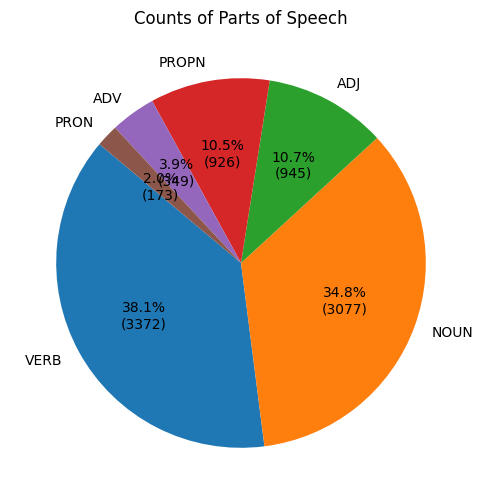

In [19]:
plot_pie(unique_fiction)

In [20]:
traditional = cleanPOSDF(traditional)

traditional = traditional[traditional['token_lower'].isin(model_traditional_100.wv.index_to_key)]

traditional['token_lower'] = traditional['token_lower'].str.replace('_', '-')
    
traditional_nouns = traditional[traditional['pos'] == 'NOUN']['token_lower'].value_counts().reset_index()
traditional_verbs = traditional[traditional['pos'] == 'VERB']['token_lower'].value_counts().reset_index()
traditional_pron = traditional[traditional['pos'] == 'PRON']['token_lower'].value_counts().reset_index()
traditional_adj = traditional[traditional['pos'] == 'ADJ']['token_lower'].value_counts().reset_index()
traditional_adv = traditional[traditional['pos'] == 'ADV']['token_lower'].value_counts().reset_index()
traditional_proper = traditional[traditional['pos'] == 'PROPN']['token_lower'].value_counts().reset_index()

unique_traditional = traditional[['token_lower', 'pos']].drop_duplicates()

In [21]:
traditional_counts = traditional['token_lower'].value_counts().reset_index(name='count')

In [22]:
traditional_POS = getTopPOS(traditional)
traditional_POS

,noun,verb,pron,adj,adv,propn
0,tao,may,siya,lahat,hindi,diyos
1,araw,sinabi,niya,walang,nang,hesus
2,sabi,dumating,ko,maraming,kaya,panginoon
3,anak,naging,kanyang,iba,di,timo
4,hari,nakita,ito,buong,lang,david
5,bahay,gusto,ako,ibang,kahit,israel
6,wala,maging,mo,pagkatapos,lamang,igorot
7,isa,ginawa,sila,malakas,ngayon,saul
8,alam,sumunod,ka,unang,nga,espanyol
9,habang,namatay,nila,malaking,dapat,pedro


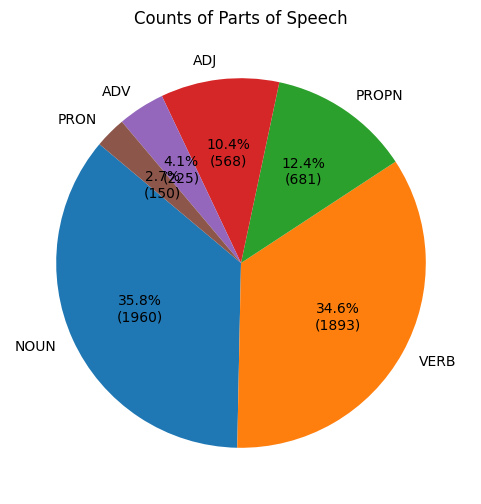

In [23]:
plot_pie(unique_traditional)

In [24]:
nonfiction = cleanPOSDF(nonfiction)

nonfiction = nonfiction[nonfiction['token_lower'].isin(model_nonfiction_100.wv.index_to_key)]

nonfiction['token_lower'] = nonfiction['token_lower'].str.replace('_', '-')

nonfiction_nouns = nonfiction[nonfiction['pos'] == 'NOUN']['token_lower'].value_counts().reset_index()
nonfiction_verbs = nonfiction[nonfiction['pos'] == 'VERB']['token_lower'].value_counts().reset_index()
nonfiction_pron = nonfiction[nonfiction['pos'] == 'PRON']['token_lower'].value_counts().reset_index()
nonfiction_adj = nonfiction[nonfiction['pos'] == 'ADJ']['token_lower'].value_counts().reset_index()
nonfiction_adv = nonfiction[nonfiction['pos'] == 'ADV']['token_lower'].value_counts().reset_index()
nonfiction_proper = nonfiction[nonfiction['pos'] == 'PROPN']['token_lower'].value_counts().reset_index()

unique_nonfiction = nonfiction[['token_lower', 'pos']].drop_duplicates()

In [25]:
nonfiction_counts = nonfiction['token_lower'].value_counts().reset_index(name='count')

In [26]:
nonfiction_POS = getTopPOS(nonfiction)
nonfiction_POS

,noun,verb,pron,adj,adv,propn
0,prayle,may,ito,maraming,nang,espanyol
1,isa,naging,siya,iba,noong,pilipino
2,bilang,maging,kanyang,ibang,hindi,pilipinas
3,galeon,dumating,niya,lahat,lamang,espanya
4,karapatan,maaaring,nila,unang,noon,maynila
5,laban,gusto,sila,walang,kaya,mabini
6,araw,umalis,kanilang,marami,de,ingles
7,loob,ginamit,siyang,bago,pang,del
8,taon,sinasabing,niyang,malaking,mas,amerikano
9,panahon,magkaroon,dito,buong,agad,jacinto


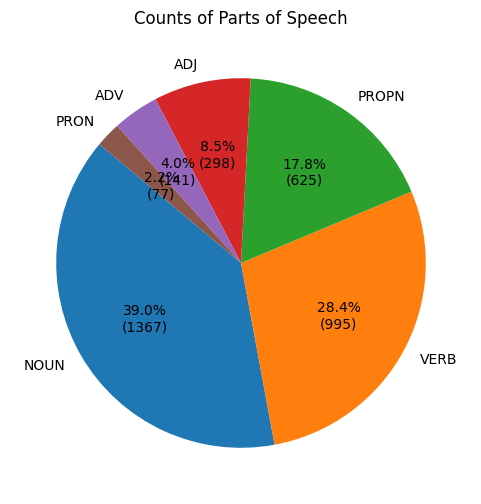

In [27]:
plot_pie(unique_nonfiction)

# Model Validation

In [28]:
# load models

model_fiction = Word2Vec.load('./txt-files/clean_fiction_agg_model_w2v.bin')
model_traditional = Word2Vec.load('./txt-files/clean_traditional_agg_model_w2v.bin')
model_nonfiction = Word2Vec.load('./txt-files/clean_nonfiction_agg_model_w2v.bin')
model_all = Word2Vec.load('./txt-files/clean_all_corpus_agg_model_w2v.bin')

In [29]:
model_fiction_50 = Word2Vec.load('./txt-files/50_clean_fiction_agg_model_w2v.bin')
model_traditional_50 = Word2Vec.load('./txt-files/50_clean_traditional_agg_model_w2v.bin')
model_nonfiction_50 = Word2Vec.load('./txt-files/50_clean_nonfiction_agg_model_w2v.bin')
model_all_50 = Word2Vec.load('./txt-files/50_clean_all_corpus_agg_model_w2v.bin')

In [30]:
model_fiction_100 = Word2Vec.load('./txt-files/100_clean_fiction_agg_model_w2v.bin')
model_traditional_100 = Word2Vec.load('./txt-files/100_clean_traditional_agg_model_w2v.bin')
model_nonfiction_100 = Word2Vec.load('./txt-files/100_clean_nonfiction_agg_model_w2v.bin')
model_all_100 = Word2Vec.load('./txt-files/100_clean_all_corpus_agg_model_w2v.bin')

In [31]:
### INITIALIZE VARIABLES ###

# Filipino gendered seed words

fil_directly_male = ['lalaki', 'lalaking', 'lalake', 'kalalakihan', 'lalakeng', 
                 'pagkalalaki', 'panlalaki', 'pagkalalake', 'kalalakihang', 
                 'panlalaking', 'pangkalalakihan',
                 'kalalaki', 'kalalaking'
                    ]
fil_directly_female = ['babae', 'babaeng', 'kababaihan', 'pagkababae', 'babaing', 
                   'kababaihang', 'pambabae', 'pambabaeng', 'makababae',
                      'kababae', 'kababaeng'
                      ]

fil_male_marked = ['ama', 'bana', 'bayaw', 'binata', 'binatang', 'binatilyo', 'biyudo', 'bulugan', 'diko', 'duke', 'emperador', 
               'G.', 'ginoo', 'hari', 'ingkong', 'konde', 'kumpadre', 'kumpare', 'kuya', 'kuyang', 'lakan', 'amang',
               'lakandiwa', 'lolo', 'mayordomo', 'monghe', 'padre', 'pare', 'pari', 'patriyarka', 'prinsipe', 'sangko',
               'sireno', 'tandang', 'tatay', 'tinali', 'tito', 'tiyo', 'tiyuhin', 'tay', 'itay', 'katipunero',
               'maghari', 'prinsipeng', 'sultan', 'manong', 'kapitan', 'kapitang',
                  'maestro', 'pastol', 'kartero', 'karterong', 'kutsero', 'kutserong', 'ninong',
                  'tinyente', 'tinyenteng', 'pinakahari', 'prinsipado', 'prinsiping', 'prinsipi', 'haring',
                   'raha', 'lakandula', 'ginoong', 'datu', 'maestrong', 'papa','mestiso'
                  ]
fil_female_marked = ['ate', 'babaylan', 'Bb.', 'binibini', 'binibining', 'biyuda', 'dalaginding', 'dalagita', 'ditse', 'dukesa', 'dumalaga',
                 'emperatris', 'ginang', 'Gng.', 'hipag', 'impo', 'ina', 'inang', 'inahin', 'kondesa', 'kumare', 'lakambini', 'dalaga',
                 'lola', 'madrasta', 'madre', 'mare', 'matriyarka', 'nanay', 'prinsesa', 'reyna', 'sanse', 'sirena', 'dalagang',
                 'tita', 'tiya', 'tiyahin', 'nay', 'inay', 'prinsesang', 'sultana', 'manang', 'maglola', 'kapitana', 'kapitanang',
                    'maybahay', 'katipunera', 'mongha', 'lolay', 'ninang',
                    'inpanta', 'diwata', 'diwatang', 'engkantada', 'engkantadang', 'rane',
                     'mama', 'maestra', 'maestrona', 'mestisa'
                    ]

fil_male = fil_directly_male + fil_male_marked
fil_female = fil_directly_female + fil_female_marked

gender_marked = fil_male+ fil_female

In [32]:
### DEFINE VARIABLES ###

# Compute cosine similarity between a word and a list of
# words pertaining to an attribute
def word_attr_sim(emb, word, attr_list):
    sum_of_sims = 0

    # check if gendered word is in embedding model vocab
    attr_list = [w for w in attr_list if w in emb.wv]

    for attr_word in attr_list:
        word_vec = np.array([emb.wv[word]])
        attr_word_vec = np.array([emb.wv[attr_word]])
        sim = cosine_similarity(word_vec, attr_word_vec)
        sum_of_sims += sim
        
    mean_sim = sum_of_sims / len(attr_list)
    
    return mean_sim

# Compute word's association with an attribute pair
def get_assoc(emb, word, attr_list_1, attr_list_2):
    return word_attr_sim(emb, word, attr_list_1) - word_attr_sim(emb, word, attr_list_2)

In [ ]:
# What percentage of male-marked words are more similar to
# directly male-denoting words compared to directly female-
# denoting ones?

def getEmbAcc(model, min_count=0):
    
    gender_assocs = pd.DataFrame(columns = ['word', 'lexical_gender', 'assoc_score', 'emb_gender_assoc', 'valid_emb_assoc', 'count'])
    
    for word in fil_male_marked:
        if word not in model.wv: continue
        lexical_gender = 'male'
        # remove word count if not important
        w_count = model.wv.get_vecattr(word, "count")
        if w_count < min_count: continue
        assoc_score = get_assoc(model, word, fil_directly_male, fil_directly_female)
        emb_gender_assoc = 'male' if assoc_score > 0 else 'female'
        valid_emb_assoc = 1 if emb_gender_assoc == lexical_gender else 0
        
        new_row = [word, lexical_gender, assoc_score, emb_gender_assoc, valid_emb_assoc, w_count]
        gender_assocs.loc[len(gender_assocs)] =  new_row
    
    for word in fil_female_marked:
        if word not in model.wv: continue
        lexical_gender = 'female'
        # remove word count if not important
        w_count = model.wv.get_vecattr(word, "count")
        if w_count < min_count: continue
        assoc_score = get_assoc(model, word, fil_directly_male, fil_directly_female)
        emb_gender_assoc = 'male' if assoc_score > 0 else 'female'
        valid_emb_assoc = 1 if emb_gender_assoc == lexical_gender else 0
        
        new_row = [word, lexical_gender, assoc_score, emb_gender_assoc, valid_emb_assoc, w_count]
        gender_assocs.loc[len(gender_assocs)] =  new_row
    
    valid_perc = np.mean(gender_assocs['valid_emb_assoc'])
    
    print_pct = f"The Filipino Children's Storybook Word2Vec embedding accurately represents the gender of {valid_perc:.2%} of chosen gender-marked seed words."
    return gender_assocs, valid_perc, print_pct

In [34]:
gender_assocs_all, all_pct, _ = getEmbAcc(model_all)
all_pct

0.4782608695652174

In [35]:
len(gender_assocs_all[gender_assocs_all['valid_emb_assoc'] == 1])

44

In [36]:
gender_assocs_fiction, fiction_pct, _ = getEmbAcc(model_fiction)
fiction_pct

0.4691358024691358

In [37]:
len(gender_assocs_fiction[gender_assocs_fiction['valid_emb_assoc'] == 1])

38

In [38]:
gender_assocs_traditional, traditional_pct, _ = getEmbAcc(model_traditional)
traditional_pct

0.3877551020408163

In [39]:
len(gender_assocs_traditional[gender_assocs_traditional['valid_emb_assoc'] == 1])

19

In [40]:
gender_assocs_nonfiction, nonfiction_pct, _ = getEmbAcc(model_nonfiction)
nonfiction_pct

0.5625

In [41]:
len(gender_assocs_nonfiction[gender_assocs_nonfiction['valid_emb_assoc'] == 1])

18

## Model 2 Validation

In [42]:
assocs, all_50_pct, _ = getEmbAcc(model_all_50)
all_50_pct

0.4891304347826087

In [43]:
gender_assocs_fiction_50, fiction_50_pct, _ = getEmbAcc(model_fiction_50)
fiction_50_pct

0.5061728395061729

In [44]:
gender_assocs_traditional_50, traditional_50_pct, _ = getEmbAcc(model_traditional_50)
traditional_50_pct

0.4897959183673469

In [45]:
gender_assocs_nonfiction_50, nonfiction_50_pct, _ = getEmbAcc(model_nonfiction_50)
nonfiction_50_pct

0.53125

## Model 3

In [46]:
assocs, all_100_pct, _ = getEmbAcc(model_all_100)
all_100_pct

0.43478260869565216

In [47]:
gender_assocs_fiction_100, fiction_100_pct, _ = getEmbAcc(model_fiction_100)
fiction_100_pct

0.49382716049382713

In [48]:
gender_assocs_traditional_100, traditional_100_pct, _ = getEmbAcc(model_traditional_100)
traditional_100_pct

0.46938775510204084

In [49]:
gender_assocs_nonfiction_100, nonfiction_100_pct, _ = getEmbAcc(model_nonfiction_100)
nonfiction_100_pct

0.59375

# Save models

In [50]:
saveW2VModel('./txt-files', 'clean_all_corpus_agg.txt', model_all)
saveW2VModel('./txt-files', 'clean_fiction_agg.txt', model_fiction)
saveW2VModel('./txt-files', 'clean_traditional_agg.txt', model_traditional)
saveW2VModel('./txt-files', 'clean_nonfiction_agg.txt', model_nonfiction)

✅ Model saved to clean_all_corpus_agg_model_w2v.bin
✅ Model saved to clean_fiction_agg_model_w2v.bin
✅ Model saved to clean_traditional_agg_model_w2v.bin
✅ Model saved to clean_nonfiction_agg_model_w2v.bin


In [51]:
saveW2VModel('./txt-files', '50_'+'clean_all_corpus_agg.txt', model_all_50)
saveW2VModel('./txt-files', '50_'+'clean_fiction_agg.txt', model_fiction_50)
saveW2VModel('./txt-files', '50_'+'clean_traditional_agg.txt', model_traditional_50)
saveW2VModel('./txt-files', '50_'+'clean_nonfiction_agg.txt', model_nonfiction_50)

✅ Model saved to 50_clean_all_corpus_agg_model_w2v.bin
✅ Model saved to 50_clean_fiction_agg_model_w2v.bin
✅ Model saved to 50_clean_traditional_agg_model_w2v.bin
✅ Model saved to 50_clean_nonfiction_agg_model_w2v.bin


In [52]:
saveW2VModel('./txt-files', '100_'+'clean_all_corpus_agg.txt', model_all_100)
saveW2VModel('./txt-files', '100_'+'clean_fiction_agg.txt', model_fiction_100)
saveW2VModel('./txt-files', '100_'+'clean_traditional_agg.txt', model_traditional_100)
saveW2VModel('./txt-files', '100_'+'clean_nonfiction_agg.txt', model_nonfiction_100)

✅ Model saved to 100_clean_all_corpus_agg_model_w2v.bin
✅ Model saved to 100_clean_fiction_agg_model_w2v.bin
✅ Model saved to 100_clean_traditional_agg_model_w2v.bin
✅ Model saved to 100_clean_nonfiction_agg_model_w2v.bin


In [50]:
# Gendered word vectors that properly capture gendered information
def getCorrectGenderedWords(gender_assocs, model): # , fil_male_marked, fil_female_marked):

    correct_fil_male = []
    correct_fil_female = []
    
    for word in fil_male_marked:
        if word not in model.wv: continue
        idx = gender_assocs[gender_assocs['word']==word].index.values.astype(int)[0]
        valid = gender_assocs.iloc[idx,4]
        if valid:
            correct_fil_male.append(word)
            
    for word in fil_female_marked:
        if word not in model.wv: continue
        idx = gender_assocs[gender_assocs['word']==word].index.values.astype(int)[0]
        valid = gender_assocs.iloc[idx,4]
        if valid:
            correct_fil_female.append(word)

    return correct_fil_male, correct_fil_female

In [51]:
corr_male_fiction, corr_female_fiction = getCorrectGenderedWords(gender_assocs_fiction, model_fiction)
corr_male_traditional, corr_female_traditional = getCorrectGenderedWords(gender_assocs_traditional, model_traditional)
corr_male_nonfiction, corr_female_nonfiction = getCorrectGenderedWords(gender_assocs_nonfiction, model_nonfiction)

corr_male_all, corr_female_all = getCorrectGenderedWords(gender_assocs_all, model_all)

corr_male_fiction_50, corr_female_fiction_50 = getCorrectGenderedWords(gender_assocs_fiction_50, model_fiction_50)
corr_male_traditional_50, corr_female_traditional_50 = getCorrectGenderedWords(gender_assocs_traditional_50, model_traditional_50)
corr_male_nonfiction_50, corr_female_nonfiction_50 = getCorrectGenderedWords(gender_assocs_nonfiction_50, model_nonfiction_50)

corr_male_fiction_100, corr_female_fiction_100 = getCorrectGenderedWords(gender_assocs_fiction_100, model_fiction_100)
corr_male_traditional_100, corr_female_traditional_100 = getCorrectGenderedWords(gender_assocs_traditional_100, model_traditional_100)
corr_male_nonfiction_100, corr_female_nonfiction_100 = getCorrectGenderedWords(gender_assocs_nonfiction_100, model_nonfiction_100)



In [52]:
print(f"male fiction: {corr_male_fiction}\n")
print(f"female fiction: {corr_female_fiction}\n")

print(f"male traditional: {corr_male_traditional}\n")
print(f"female traditional: {corr_female_traditional}\n")

print(f"male nonfiction: {corr_male_nonfiction}\n")
print(f"female nonfiction: {corr_female_nonfiction}\n")

print(f"male all: {corr_male_all}\n")
print(f"female all: {corr_female_all}\n")

print(f"male fiction 50: {corr_male_fiction_50}\n")
print(f"female fiction 50: {corr_female_fiction_50}\n")

print(f"male traditional 50: {corr_male_traditional_50}\n")
print(f"female traditional 50: {corr_female_traditional_50}\n")

print(f"male nonfiction 50: {corr_male_nonfiction_50}\n")
print(f"female nonfiction 50: {corr_female_nonfiction_50}\n")

print(f"male fiction 100: {corr_male_fiction_100}\n")
print(f"female fiction 100: {corr_female_fiction_100}\n")

print(f"male traditional 100: {corr_male_traditional_100}\n")
print(f"female traditional 100: {corr_female_traditional_100}\n")

print(f"male nonfiction 100: {corr_male_nonfiction_100}\n")
print(f"female nonfiction 100: {corr_female_nonfiction_100}\n")

male fiction: ['binata', 'duke', 'konde', 'kuya', 'lolo', 'mayordomo', 'padre', 'tandang', 'tatay', 'tito', 'tay', 'itay', 'prinsipeng', 'sultan', 'kapitang', 'kartero', 'prinsipado', 'haring', 'papa']

female fiction: ['binibining', 'ginang', 'hipag', 'impo', 'inang', 'dalaga', 'prinsesa', 'sirena', 'dalagang', 'nay', 'maglola', 'maybahay', 'mongha', 'lolay', 'inpanta', 'engkantada', 'engkantadang', 'rane', 'maestra']

male traditional: ['ama', 'binata', 'ginoo', 'hari', 'amang', 'lolo', 'pari', 'tiyo', 'itay', 'pastol', 'kartero', 'ninong', 'haring']

female traditional: ['ate', 'inang', 'lola', 'nanay', 'nay', 'inay']

male nonfiction: ['ama', 'emperador', 'ginoo', 'hari', 'amang', 'lolo', 'pari', 'tiyo', 'kapitan', 'ninong', 'haring', 'papa']

female nonfiction: ['inang', 'lakambini', 'prinsesa', 'dalagang', 'maybahay', 'katipunera']

male all: ['ama', 'bayaw', 'binata', 'binatang', 'ginoo', 'hari', 'konde', 'kuya', 'kuyang', 'amang', 'lolo', 'monghe', 'tandang', 'tinali', 'tito', 

## Gender Semantic Neighborhood analysis (START HERE)

In [53]:
# load models

model_fiction = Word2Vec.load('./txt-files/clean_fiction_agg_model_w2v.bin')
model_traditional = Word2Vec.load('./txt-files/clean_traditional_agg_model_w2v.bin')
model_nonfiction = Word2Vec.load('./txt-files/clean_nonfiction_agg_model_w2v.bin')
model_all = Word2Vec.load('./txt-files/clean_all_corpus_agg_model_w2v.bin')

In [54]:
# -----------------------------
# 1. Build centroid
# -----------------------------
def build_centroid(model, seed_words):
    # returns centroid vector computed form all valid seed words
    valid = [w for w in seed_words if w in model.wv.index_to_key]

    if len(valid) == 0:
        raise ValueError('No seed words found in vocabulary')

    vectors = np.array([model.wv[w] for w in valid])
    centroid = np.mean(vectors, axis=0)

    return centroid, valid


## Iterative for loop version

In [ ]:
### Get word count of gender seeds

fil_directly_male = ['lalaki', 'lalaking', 'lalake', 'kalalakihan', 'lalakeng', 
                 'pagkalalaki', 'panlalaki', 'pagkalalake', 'kalalakihang', 
                 'panlalaking', 'pangkalalakihan']
fil_directly_female = ['babae', 'babaeng', 'kababaihan', 'pagkababae', 'babaing', 
                   'kababaihang', 'pambabae', 'pambabaeng', 'kababaihan', 'makababae']

extra_male = ['ama', 'amang', 'tatay', 'tay', 'itay', 'kuya', 'kuyang',
             'lolo', 'tito', 'tiyo', 'binata', 'binatang', 'ginoo', 'ginoong', 'ninong']

extra_female = ['ina', 'inang', 'inahin', 'nanay', 'nay', 'inay', 'ate',
               'lola', 'tita', 'tiya', 'dalaga', 'dalagang', 'dalagita',
               'binibini', 'binibining', 'ginang', 'donya', 'doña', 'lolay', 'ninang']

words = fil_directly_male + fil_directly_female + extra_male + extra_female

pattern = r"\b(" + "|".join(words) + r")\b"


## RND for getting which are associated

In [ ]:
def compute_rnd(
    model,
    male_centroid,
    female_centroid,
    exclude_words=None
):
    """
    Compute Relative Norm Distance (RND) for the union of male and
    female semantic neighbors.
    """
    if exclude_words is None:
        exclude_words = []
        
    male_centroid = male_centroid.reshape(1, -1)
    female_centroid = female_centroid.reshape(1, -1)

    target_words = model.wv.index_to_key

    results = []

    for word in target_words:

        if word not in model.wv:
            continue
        if word in exclude_words:
            continue

        vec = model.wv[word].reshape(1, -1)

        male_sim = cosine_similarity(
            vec,
            male_centroid
        )[0][0]

        female_sim = cosine_similarity(
            vec,
            female_centroid
        )[0][0]

        rnd = male_sim - female_sim

        if rnd > 0:
            association = "Male"
        elif rnd < 0:
            association = "Female"
        else:
            association = "Neutral"

        results.append({
            "word": word,
            "male_similarity": male_sim,
            "female_similarity": female_sim,
            "RND": rnd,
            "abs_RND": abs(rnd),
            "association": association
        })

    df = pd.DataFrame(results)

    df = df.sort_values(
        by="abs_RND",
        ascending=False
    ).reset_index(drop=True)

    return df

### Run on every genre model

In [ ]:
genre_models = {
    "fiction": {
        "model": model_fiction_100,
        "male": fil_directly_male + corr_male_fiction_100,
        "female": fil_directly_female + corr_female_fiction_100
    },
    "traditional": {
        "model": model_traditional_100,
        "male": fil_directly_male + corr_male_traditional_100,
        "female": fil_directly_female + corr_female_traditional_100
    },
    "nonfiction": {
        "model": model_nonfiction_100,
        "male": fil_directly_male + corr_male_nonfiction_100,
        "female": fil_directly_female + corr_female_nonfiction_100
    },
}

male_seeds = fil_directly_male + fil_male_marked#+ extra_male
female_seeds = fil_directly_female + fil_female_marked#+ extra_female

male_seeds = fil_directly_male
female_seeds = fil_directly_female

exclude_words = male_seeds + female_seeds

rnd_results = {}

for genre, model in genre_models.items():

    print(f"Processing {genre}...")

    male_centroid, valid_male = build_centroid(
        # model,
        # male_seeds

        model["model"],
        model["male"]
    )

    female_centroid, valid_female = build_centroid(
        # model,
        # female_seeds

        model["model"],
        model["female"]
    )

    # exclude_words = set(valid_male) | set(fil_male_marked) | set(valid_female) | set(fil_female_marked)
    exclude_words = set(valid_male) | set(valid_female)
    rnd_df = compute_rnd(
        model["model"],
        male_centroid,
        female_centroid,
        exclude_words
    )

    rnd_results[genre] = rnd_df

Processing fiction...
Processing traditional...
Processing nonfiction...


In [58]:
rnd_fiction = rnd_results["fiction"]
rnd_traditional = rnd_results["traditional"]
rnd_nonfiction = rnd_results["nonfiction"]

In [59]:
rnd_fiction['word'] = rnd_fiction['word'].str.replace("_", "-")
rnd_traditional['word'] = rnd_traditional['word'].str.replace("_", "-")
rnd_nonfiction['word'] = rnd_nonfiction['word'].str.replace("_", "-")

### Save RND Results to csv

In [60]:
rnd_fiction.to_csv('./rnd-files/rnd_fiction_all_agg_100.csv', index=False)
rnd_traditional.to_csv('./rnd-files/rnd_traditional_all_agg_100.csv', index=False)
rnd_nonfiction.to_csv('./rnd-files/rnd_nonfiction_all_agg_100.csv', index=False)

### Load RND Results from csv

In [61]:
rnd_fiction = pd.read_csv('./rnd-files/rnd_fiction_all_agg_100.csv')
rnd_traditional = pd.read_csv('./rnd-files/rnd_traditional_all_agg_100.csv')
rnd_nonfiction = pd.read_csv('./rnd-files/rnd_nonfiction_all_agg_100.csv')

In [62]:
rnd_fiction_m = rnd_fiction[rnd_fiction['association'] == 'Male']
rnd_fiction_m[:30]

,word,male_similarity,female_similarity,RND,abs_RND,association
4,pagkapasok,0.467448,0.226997,0.240451,0.240451,Male
5,alok,0.538660,0.299725,0.238935,0.238935,Male
8,mmmm,0.646250,0.411787,0.234463,0.234463,Male
10,kulungan,0.448277,0.214730,0.233548,0.233548,Male
11,o-o-range,0.617127,0.383942,0.233184,0.233184,Male
13,aa,0.414241,0.181817,0.232424,0.232424,Male
14,umupo,0.405231,0.174706,0.230525,0.230525,Male
16,o-o-riole,0.631714,0.403478,0.228236,0.228236,Male
18,hinamon,0.549060,0.321970,0.227090,0.227090,Male
19,pagbalik,0.442183,0.215715,0.226468,0.226468,Male


In [63]:
rnd_fiction_f = rnd_fiction[rnd_fiction['association'] == 'Female']
rnd_fiction_f[:30]

,word,male_similarity,female_similarity,RND,abs_RND,association
0,abang,0.233180,0.537262,-0.304082,0.304082,Female
1,binasa,0.204073,0.463765,-0.259691,0.259691,Female
2,yata,0.225420,0.480179,-0.254759,0.254759,Female
3,nalulungkot,0.269472,0.512969,-0.243497,0.243497,Female
6,mapansin,0.237391,0.475706,-0.238315,0.238315,Female
7,silahis,0.313090,0.551230,-0.238140,0.238140,Female
9,magdaramdam,0.341959,0.575822,-0.233863,0.233863,Female
12,maaalis,0.300756,0.533746,-0.232990,0.232990,Female
15,manunumbalik,0.171394,0.400050,-0.228656,0.228656,Female
17,raha,0.331958,0.559328,-0.227370,0.227370,Female


In [64]:
rnd_traditional_m = rnd_traditional[rnd_traditional['association'] == 'Male']
rnd_traditional_m[:30]

,word,male_similarity,female_similarity,RND,abs_RND,association
8,tatawaging,0.553468,0.290336,0.263132,0.263132,Male
19,nanatiling,0.433973,0.192465,0.241508,0.241508,Male
23,binihag,0.596911,0.363407,0.233503,0.233503,Male
29,matandang,0.490181,0.262935,0.227247,0.227247,Male
30,doeg,0.655501,0.428341,0.227160,0.227160,Male
44,balahibo,0.442207,0.221916,0.220291,0.220291,Male
48,balat,0.392135,0.173722,0.218413,0.218413,Male
50,darius,0.493645,0.277786,0.215859,0.215859,Male
53,pinatay,0.517256,0.302915,0.214341,0.214341,Male
56,tiwala,0.441611,0.228683,0.212927,0.212927,Male


In [65]:
rnd_traditional_f = rnd_traditional[rnd_traditional['association'] == 'Female']
rnd_traditional_f[:30]

,word,male_similarity,female_similarity,RND,abs_RND,association
0,pagtataka,0.200727,0.520591,-0.319864,0.319864,Female
1,kakaiba,0.218989,0.515672,-0.296683,0.296683,Female
2,ubos-lakas,0.274945,0.567646,-0.292701,0.292701,Female
3,kausap,0.278158,0.567627,-0.289469,0.289469,Female
4,puyat,0.275871,0.555690,-0.279819,0.279819,Female
5,tanungin,0.193044,0.469200,-0.276156,0.276156,Female
6,mapawi,0.250398,0.522260,-0.271862,0.271862,Female
7,pagiyak,0.332952,0.602553,-0.269601,0.269601,Female
9,pumuslit,0.212435,0.474694,-0.262259,0.262259,Female
10,binata,0.199213,0.458258,-0.259045,0.259045,Female


In [66]:
rnd_nonfiction_m = rnd_nonfiction[rnd_nonfiction['association'] == 'Male']
rnd_nonfiction_m[:30]

,word,male_similarity,female_similarity,RND,abs_RND,association
0,magkasakit,0.510527,0.163200,0.347327,0.347327,Male
1,maranan,0.642624,0.306889,0.335735,0.335735,Male
2,kawani,0.742712,0.414545,0.328166,0.328166,Male
3,bunsong,0.643313,0.316955,0.326358,0.326358,Male
4,lumangoy,0.538643,0.214478,0.324165,0.324165,Male
5,napangiti,0.652434,0.339600,0.312835,0.312835,Male
7,diba,0.557805,0.267744,0.290061,0.290061,Male
8,pinagmamasdan,0.692671,0.403105,0.289566,0.289566,Male
9,hinampas,0.538778,0.252197,0.286581,0.286581,Male
10,lumaking,0.569420,0.283884,0.285536,0.285536,Male


In [67]:
rnd_nonfiction_f = rnd_nonfiction[rnd_nonfiction['association'] == 'Female']
rnd_nonfiction_f[:30]

,word,male_similarity,female_similarity,RND,abs_RND,association
6,urduja,0.463510,0.755306,-0.291796,0.291796,Female
78,binuksan,0.392479,0.622477,-0.229998,0.229998,Female
136,pagpapahalaga,0.445348,0.658230,-0.212882,0.212882,Female
150,taga-malolos,0.353990,0.562842,-0.208852,0.208852,Female
185,pakasalan,0.505236,0.705845,-0.200609,0.200609,Female
294,panggabing,0.443843,0.625692,-0.181849,0.181849,Female
303,naipamalas,0.476872,0.657538,-0.180666,0.180666,Female
332,pandacan,0.430265,0.607437,-0.177173,0.177173,Female
340,iniukol,0.497228,0.672842,-0.175614,0.175614,Female
380,pagtanggap,0.324542,0.494002,-0.169460,0.169460,Female


### Save to CSV

In [68]:
rnd_fiction_m[['word', 'RND', 'association']].to_csv('./rnd-files/rnd_fiction_m_agg_100.csv', index=False)
rnd_traditional_m[['word', 'RND', 'association']].to_csv('./rnd-files/rnd_traditional_m_agg_100.csv', index=False)
rnd_nonfiction_m[['word', 'RND', 'association']].to_csv('./rnd-files/rnd_nonfiction_m_agg_100.csv', index=False)

rnd_fiction_f[['word', 'RND', 'association']].to_csv('./rnd-files/rnd_fiction_f_agg_100.csv', index=False)
rnd_traditional_f[['word', 'RND', 'association']].to_csv('./rnd-files/rnd_traditional_f_agg_100.csv', index=False)
rnd_nonfiction_f[['word', 'RND', 'association']].to_csv('./rnd-files/rnd_nonfiction_f_agg_100.csv', index=False)

## Visualize RND

In [ ]:
rnd_fiction_m = pd.read_csv('./rnd-files/rnd_fiction_m_clean.csv')
rnd_traditional_m = pd.read_csv('./rnd-files/rnd_traditional_m_clean.csv')
rnd_nonfiction_m = pd.read_csv('./rnd-files/rnd_nonfiction_m_clean.csv')

rnd_fiction_f = pd.read_csv('./rnd-files/rnd_fiction_f_clean.csv')
rnd_traditional_f = pd.read_csv('./rnd-files/rnd_traditional_f_clean.csv')
rnd_nonfiction_f = pd.read_csv('./rnd-files/rnd_nonfiction_f_clean.csv')

In [69]:
rnd_fiction = pd.concat([rnd_fiction_m[['word', 'RND', 'association']], rnd_fiction_f[['word', 'RND', 'association']]], axis=0, ignore_index=True)
rnd_traditional = pd.concat([rnd_traditional_m[['word', 'RND', 'association']], rnd_traditional_f[['word', 'RND', 'association']]], axis=0, ignore_index=True)
rnd_nonfiction = pd.concat([rnd_nonfiction_m[['word', 'RND', 'association']], rnd_nonfiction_f[['word', 'RND', 'association']]], axis=0, ignore_index=True)


In [ ]:
def plot_rnd(
    rnd_df,
    top_n=15,
    title="Relative Norm Distance (RND)"
):

    male = rnd_df.sort_values(by='RND', ascending=True)[-top_n:]
    female = rnd_df.sort_values(by='RND', ascending=True)[:top_n]

    plot_df = pd.concat([female, male])
    # print(plot_df)

    colors = [
        "hotpink" if x < 0 else "royalblue"
        for x in plot_df["RND"]
    ]

    plt.figure(figsize=(5, 7))   

    plt.barh(
        plot_df["word"],
        plot_df["RND"],
        color=colors
    )

    plt.axvline(
        x=0,
        color="black",
        linewidth=1
    )

    plt.xlabel("Relative Norm Distance (RND)")
    plt.ylabel("Words")
    plt.title(title)

    plt.tight_layout()
    plt.show()

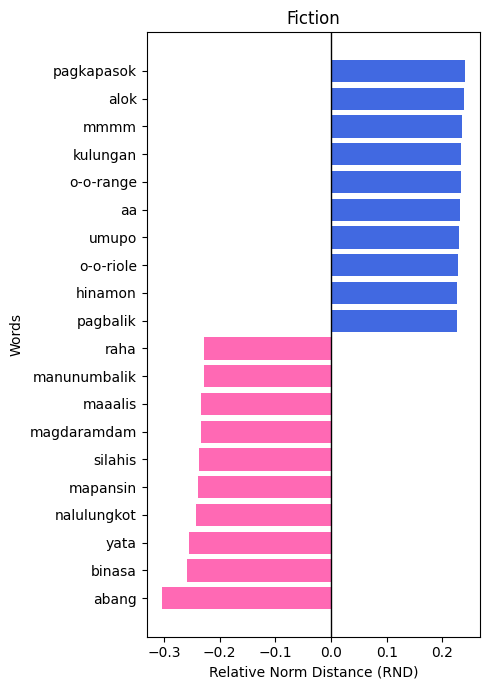

In [71]:
plot_rnd(rnd_fiction, 10, 'Fiction')

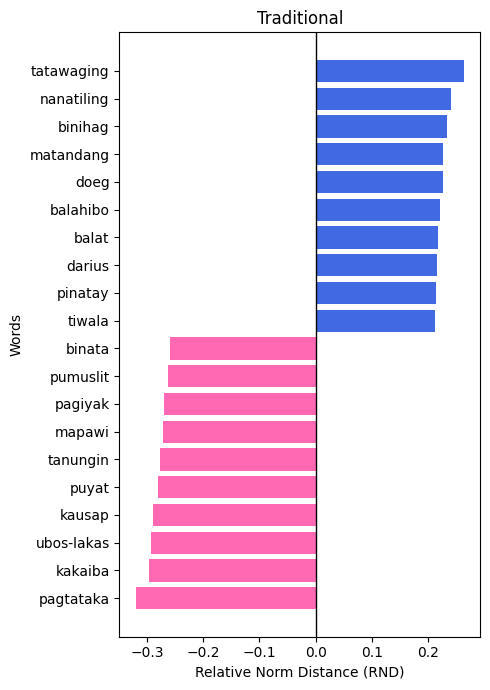

In [72]:
plot_rnd(rnd_traditional, 10, 'Traditional')

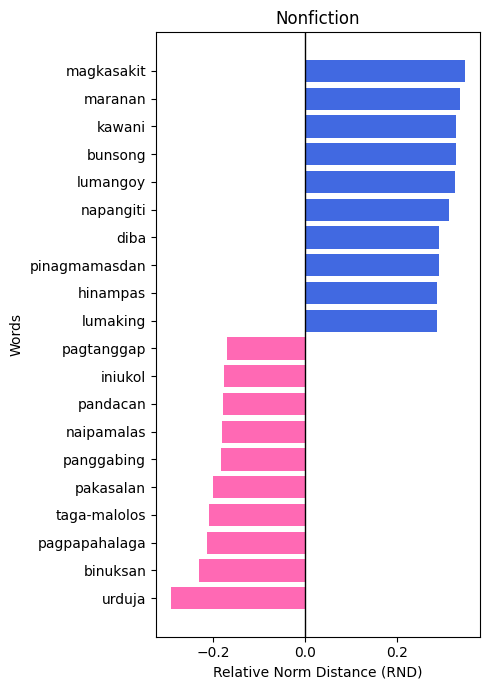

In [73]:
plot_rnd(rnd_nonfiction, 10, 'Nonfiction')

In [74]:
rnd_fiction['genregrp'] = 'Fiction'
rnd_traditional['genregrp'] = 'Traditional'
rnd_nonfiction['genregrp'] = 'Nonfiction'

In [75]:
rnd_fiction['genregrp'][0]

'Fiction'

### RND results gender associations

In [76]:
import math

def genregrp_distribution_plots(dfrnd_results_list):
    n = len(dfrnd_results_list)
    
    # Determine grid size (square-like)
    cols = math.ceil(math.sqrt(n))
    rows = math.ceil(n / cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 6, rows * 5))
    axes = np.array(axes).reshape(-1)
    
    for i, dfrnd_results in enumerate(dfrnd_results_list):
        ax = axes[i]
        
        # Extract RND scores
        rnd = dfrnd_results["RND"].dropna().values
        
        # Compute statistics
        mean_rnd = np.mean(rnd)
        std_rnd = np.std(rnd)
        
        # Split by gender association
        rnd_masc = dfrnd_results[dfrnd_results["association"] == "Male"]["RND"]
        rnd_fem  = dfrnd_results[dfrnd_results["association"] == "Female"]["RND"]
        
        # Feminine histogram
        ax.hist(
            rnd_fem,
            bins=20,
            alpha=0.7,
            label="Female",
            edgecolor='black',
            color='purple'
        )
        
        # Masculine histogram
        ax.hist(
            rnd_masc,
            bins=20,
            alpha=0.7,
            label="Male",
            edgecolor='black',
            color='blue'
        )
        
        # Mean line
        ax.axvline(
            mean_rnd,
            linestyle="dashed",
            linewidth=2,
            label="Mean",
            color='black'
        )
        
        # ±2 SD lines
        ax.axvline(
            mean_rnd + 2 * std_rnd,
            linewidth=2,
            label="+2 SD",
            color='green'
        )
        
        ax.axvline(
            mean_rnd - 2 * std_rnd,
            linewidth=2,
            label="-2 SD",
            color='green'
        )
        
        ax.set_xlabel("RND Association Score")
        ax.set_ylabel("Word Count")
        ax.set_title(dfrnd_results['genregrp'][0])
        ax.legend()
        
        print(dfrnd_results['genregrp'][0])
        print("Mean association:", mean_rnd)
        print("z-score +2 SD:", mean_rnd + 2 * std_rnd)
        print("z-score -2 SD:", mean_rnd - 2 * std_rnd)
    
    # Remove unused subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.show()

Fiction
Mean association: -0.003308693983577292
z-score +2 SD: 0.14598889852513758
z-score -2 SD: -0.1526062864922922
Traditional
Mean association: -0.01539644834806182
z-score +2 SD: 0.14873963563706305
z-score -2 SD: -0.17953253233318667
Nonfiction
Mean association: 0.07086157384822989
z-score +2 SD: 0.2353246596939908
z-score -2 SD: -0.09360151199753103


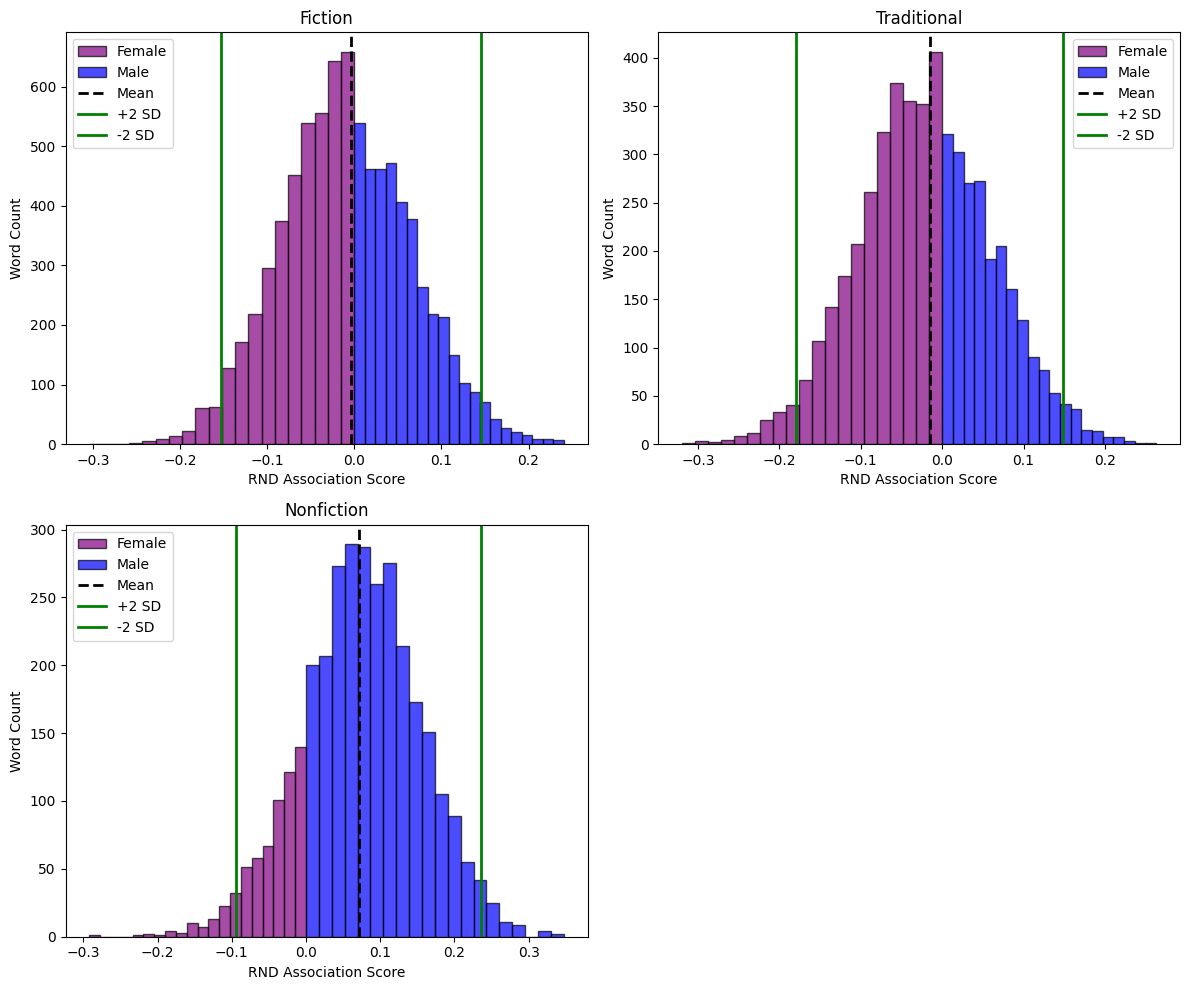

In [77]:
genregrp_distribution_plots([rnd_fiction, rnd_traditional, rnd_nonfiction])
# genre grp 1: fiction, genre grp 2: traditional, genre grp 3: nonfiction

In [78]:
gendercountpctF = rnd_fiction['association'].value_counts(normalize=True)
gendercountpctT = rnd_traditional['association'].value_counts(normalize=True)
gendercountpctNF = rnd_nonfiction['association'].value_counts(normalize=True)

gendercountF = rnd_fiction['association'].value_counts()
gendercountT = rnd_traditional['association'].value_counts()
gendercountNF = rnd_nonfiction['association'].value_counts()

print(gendercountpctF)
print(gendercountpctT)
print(gendercountpctNF)

print(gendercountF)
print(gendercountT)
print(gendercountNF)

association
Female    0.515809
Male      0.484191
Name: proportion, dtype: float64
association
Female    0.568597
Male      0.431403
Name: proportion, dtype: float64
association
Male      0.807925
Female    0.192075
Name: proportion, dtype: float64
association
Female    4209
Male      3951
Name: count, dtype: int64
association
Female    2897
Male      2198
Name: count, dtype: int64
association
Male      2671
Female     635
Name: count, dtype: int64


### RND BY POS

In [79]:
unique_fiction.rename(columns={"token_lower": "word"}, inplace=True)
unique_traditional.rename(columns={"token_lower": "word"}, inplace=True)
unique_nonfiction.rename(columns={"token_lower": "word"}, inplace=True)

In [80]:
unique_fiction

,word,pos
354,parehong,ADJ
355,pilipino,PROPN
356,ang,X
357,mga,X
358,magulang,NOUN
...,...,...
405360,oksiheno,PROPN
405490,pagtakhan,VERB
405678,pansindi,NOUN
405736,malit,ADV


In [81]:
fiction_pos_rnd = unique_fiction.merge(rnd_fiction[['word', 'RND', 'association', 'genregrp']])
traditional_pos_rnd = unique_traditional.merge(rnd_traditional[['word', 'RND', 'association', 'genregrp']])
nonfiction_pos_rnd = unique_nonfiction.merge(rnd_nonfiction[['word', 'RND', 'association', 'genregrp']])

In [82]:
fiction_pos_rnd

,word,pos,RND,association,genregrp
0,parehong,ADJ,-0.045880,Female,Fiction
1,pilipino,PROPN,-0.120269,Female,Fiction
2,ang,X,-0.044220,Female,Fiction
3,mga,X,-0.002421,Female,Fiction
4,magulang,NOUN,-0.011017,Female,Fiction
...,...,...,...,...,...
8894,oksiheno,PROPN,0.030836,Male,Fiction
8895,pagtakhan,VERB,0.045214,Male,Fiction
8896,pansindi,NOUN,0.091918,Male,Fiction
8897,malit,ADV,0.155659,Male,Fiction


In [83]:
traditional_pos_rnd

,word,pos,RND,association,genregrp
0,gusto,VERB,0.079396,Male,Traditional
1,ko,PRON,0.004636,Male,Traditional
2,nang,ADV,-0.053018,Female,Traditional
3,lumabas,VERB,-0.008602,Female,Traditional
4,dahil,SCONJ,-0.000271,Female,Traditional
...,...,...,...,...,...
5534,gamba,NOUN,-0.085923,Female,Traditional
5535,luhaang,ADV,-0.042121,Female,Traditional
5536,kalapati,PROPN,0.003595,Male,Traditional
5537,asul,PROPN,-0.089752,Female,Traditional


In [84]:
nonfiction_pos_rnd

,word,pos,RND,association,genregrp
0,higit,ADV,0.071088,Male,Nonfiction
1,pa,PART,0.151973,Male,Nonfiction
2,sa,PREP,0.038026,Male,Nonfiction
3,mga,X,-0.019757,Female,Nonfiction
4,na,PART,0.102309,Male,Nonfiction
...,...,...,...,...,...
3521,ikapapahamak,VERB,0.055796,Male,Nonfiction
3522,kaalamang,NOUN,0.119041,Male,Nonfiction
3523,makatanggap,VERB,0.198385,Male,Nonfiction
3524,convention,PROPN,0.070602,Male,Nonfiction


In [ ]:
allowed_pos = {'NOUN', 'VERB', 'PRON', 'ADJ', 'ADV', 'PROPN'}
# select_POS = ['NOUN', 'VERB', 'PRON', 'ADJ', 'ADV', 'PROPN']
def genregrp_barplots(dfrnd_results_list):
    n = len(dfrnd_results_list)
    
    # Determine grid size (square-like)
    # cols = math.ceil(math.sqrt(n))
    # rows = math.ceil(n / cols)
    
    # arrange plots horizontally
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 5), sharey=True)
    
    # Flatten axes for easy iteration
    axes = np.array(axes).reshape(-1)
    
    for i, dfrnd_results in enumerate(dfrnd_results_list):
        ax = axes[i]
        
        df_plot = dfrnd_results[dfrnd_results['pos'].isin(allowed_pos)]
        
        count_df = (
            df_plot
            .groupby(["pos", "association"])
            .size()
            .unstack(fill_value=0)
        )
        
        # Ensure both columns exist
        for col in ["Male", "Female"]:
            if col not in count_df:
                count_df[col] = 0
        
        total_words = count_df.values.sum()
        perc_df = (count_df / total_words) * 100
        # perc_df = f'{perc_df:.2f}'
        perc_df = perc_df.loc[sorted(perc_df.index)]
        
        pos_labels = perc_df.index.tolist()
        masc_perc = perc_df["Male"].values
        fem_perc  = perc_df["Female"].values
        
        y = np.arange(len(pos_labels))
        bar_height = 0.35
        
        ax.barh(
            y - bar_height / 2,
            masc_perc,
            height=bar_height,
            label="Male (%)",
            color='blue'
        )
        
        ax.barh(
            y + bar_height / 2,
            fem_perc,
            height=bar_height,
            label="Female (%)",
            color='purple'
        )
        
        ax.set_yticks(y)
        ax.set_yticklabels(pos_labels)
        ax.set_xlabel("Percentage of Total Words")
        ax.set_title(dfrnd_results['genregrp'][0])
        ax.legend()
        
        print(dfrnd_results['genregrp'][0])
        print(perc_df)
    
    # Hide unused subplots if any
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])
    
    plt.tight_layout()
    plt.show()

Fiction
association     Female       Male
pos                              
ADJ           5.883024   4.868316
ADV           2.200433   1.755786
NOUN         17.842891  16.759777
PRON          1.140121   0.820887
PROPN         3.545776   6.760917
VERB         21.103637  17.318436
Traditional
association     Female       Male
pos                              
ADJ           5.690608   4.751381
ADV           2.596685   1.528545
NOUN         19.834254  15.727440
PRON          1.860037   0.902394
PROPN         6.906077   5.377532
VERB         19.723757  15.101289
Nonfiction
association    Female       Male
pos                             
ADJ          1.902017   6.685879
ADV          0.489914   3.573487
NOUN         8.731988  30.028818
PRON         0.345821   1.873199
PROPN        2.910663  14.812680
VERB         4.870317  23.775216


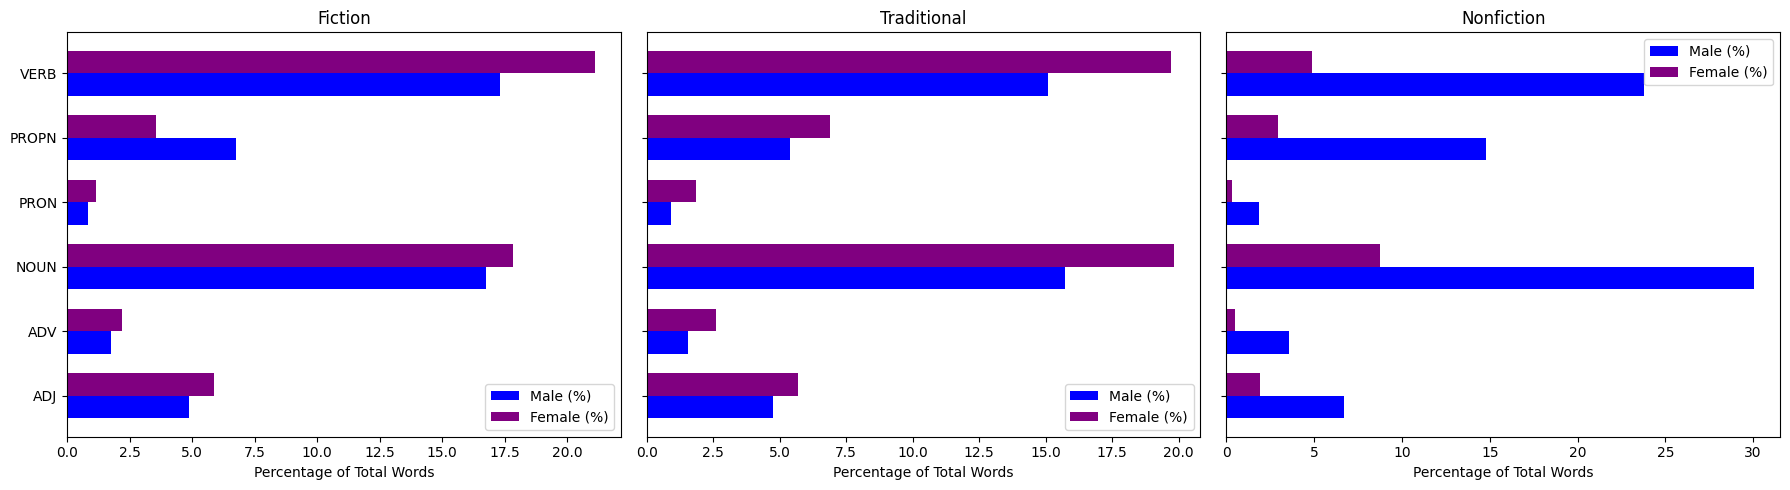

In [92]:
genregrp_barplots([fiction_pos_rnd, traditional_pos_rnd, nonfiction_pos_rnd])

## Ranked lists by POS per Genre Group (NOUN, VERB, ADJ, ADV, PROPN, PRON)

In [90]:
def getRankedPOSLists(df):
    POS = ['NOUN', 'VERB', 'ADJ', 'ADV', 'PROPN', 'PRON']
    
    for p in POS:
        output_male = df[(df['pos'] == p) & (df['association'] == 'Male')].sort_values(by='RND', ascending=False)[:10]
        output_female = df[(df['pos'] == p) & (df['association'] == 'Female')].sort_values(by='RND', ascending=True)[:10]
        print(output_male)
        print('\n')
        print(output_female)

In [91]:
getRankedPOSLists(fiction_pos_rnd)

            word   pos       RND association genregrp
3286  pagkapasok  NOUN  0.240451        Male  Fiction
3314        alok  NOUN  0.238935        Male  Fiction
1360    kulungan  NOUN  0.233548        Male  Fiction
2323    pagbalik  NOUN  0.226468        Male  Fiction
6190   pag-andar  NOUN  0.224589        Male  Fiction
2116       narra  NOUN  0.210387        Male  Fiction
6020        amag  NOUN  0.209312        Male  Fiction
5073       tahol  NOUN  0.202904        Male  Fiction
71         balik  NOUN  0.201211        Male  Fiction
6065        piko  NOUN  0.193760        Male  Fiction


             word   pos       RND association genregrp
6827        abang  NOUN -0.304082      Female  Fiction
284       silahis  NOUN -0.238140      Female  Fiction
8791         raha  NOUN -0.227370      Female  Fiction
6757  taong-bayan  NOUN -0.220461      Female  Fiction
8786       rahang  NOUN -0.213413      Female  Fiction
604          isda  NOUN -0.210439      Female  Fiction
2805   paghakbang  

In [92]:
getRankedPOSLists(traditional_pos_rnd)

          word   pos       RND association     genregrp
2512  balahibo  NOUN  0.220291        Male  Traditional
686      balat  NOUN  0.218413        Male  Traditional
3471    tiwala  NOUN  0.212927        Male  Traditional
4566   pagkuha  NOUN  0.199834        Male  Traditional
724      lakas  NOUN  0.197619        Male  Traditional
1387     sakop  NOUN  0.196433        Male  Traditional
2665   hinaing  NOUN  0.195558        Male  Traditional
2577     kalye  NOUN  0.194187        Male  Traditional
3913   linikha  NOUN  0.191706        Male  Traditional
315     balang  NOUN  0.184870        Male  Traditional


           word   pos       RND association     genregrp
1315  pagtataka  NOUN -0.319864      Female  Traditional
539      kausap  NOUN -0.289469      Female  Traditional
5055    pagiyak  NOUN -0.269601      Female  Traditional
1371     binata  NOUN -0.259045      Female  Traditional
5343      sampa  NOUN -0.252854      Female  Traditional
5335   dahilang  NOUN -0.252677      Fem

In [93]:
getRankedPOSLists(nonfiction_pos_rnd)

          word   pos       RND association    genregrp
2554    kawani  NOUN  0.328166        Male  Nonfiction
2518   bunsong  NOUN  0.326358        Male  Nonfiction
435      trunk  NOUN  0.281837        Male  Nonfiction
2591   malarya  NOUN  0.280106        Male  Nonfiction
2126      alok  NOUN  0.279623        Male  Nonfiction
245      balat  NOUN  0.263911        Male  Nonfiction
315   pangarap  NOUN  0.263656        Male  Nonfiction
271   salaysay  NOUN  0.262946        Male  Nonfiction
428      tiyan  NOUN  0.261232        Male  Nonfiction
2555     inang  NOUN  0.258353        Male  Nonfiction


               word   pos       RND association    genregrp
1393  pagpapahalaga  NOUN -0.212882      Female  Nonfiction
1432   taga-malolos  NOUN -0.208852      Female  Nonfiction
1435     panggabing  NOUN -0.181849      Female  Nonfiction
1500     pagtanggap  NOUN -0.169460      Female  Nonfiction
1066        hakbang  NOUN -0.168892      Female  Nonfiction
475           tulad  NOUN -0.1668

## PLOT RND POS

In [94]:
def plot_rnd_pos(
    rnd_df_list,
    pos,
    top_n=15
):
    n = len(rnd_df_list)
    cols = 3
    rows = math.ceil(n/cols)

    fig, axes = plt.subplots(rows, cols, figsize=(12, 5 * rows))
    axes = np.array(axes).flatten()  # Flatten in case of multiple rows

    for i, rnd_df in enumerate(rnd_df_list):

        # male = rnd_df.nlargest(top_n, "RND")
        # female = rnd_df.nsmallest(top_n, "RND")
        rnd_df = rnd_df[rnd_df['pos'] == pos]
        male = rnd_df.sort_values(by='RND', ascending=True)[-top_n:]
        female = rnd_df.sort_values(by='RND', ascending=True)[:top_n]
    
        plot_df = pd.concat([female, male])
        # print(plot_df)
    
        colors = [
            "hotpink" if x < 0 else "royalblue"
            for x in plot_df["RND"]
        ]

        ax = axes[i]
    
        # ax.figure(figsize=(5, 7))   
    
        ax.barh(
            plot_df["word"],
            plot_df["RND"],
            color=colors
        )
    
        ax.axvline(
            x=0,
            color="black",
            linewidth=1
        )
        genre = plot_df['genregrp'].unique()[0]
    
        ax.set_xlabel("Relative Norm Distance (RND)")
        ax.set_ylabel("Words")
        ax.set_title(f"{pos} - {genre}")
    
    plt.tight_layout()
    plt.show()

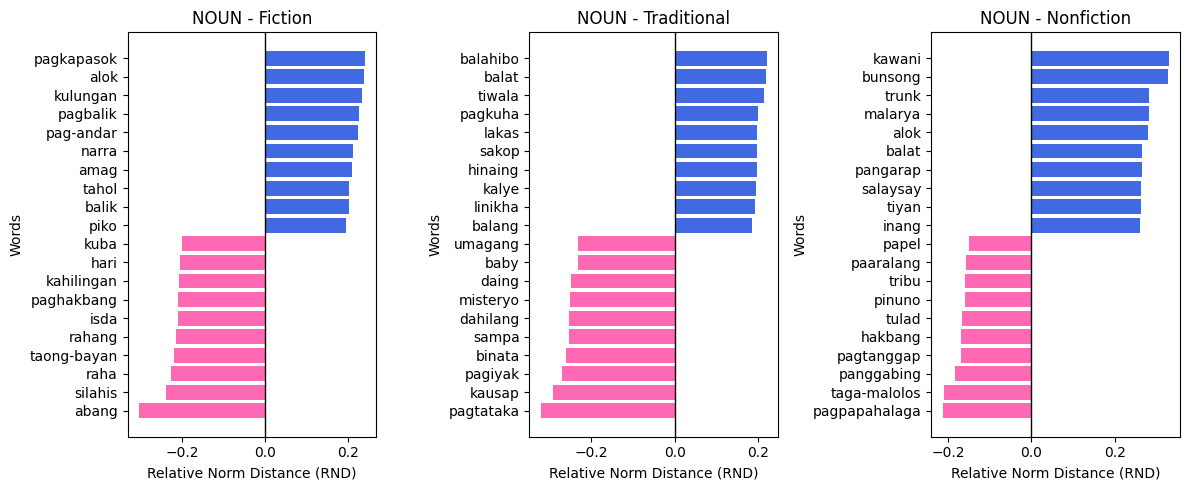

In [95]:
rnd_list = [fiction_pos_rnd, traditional_pos_rnd, nonfiction_pos_rnd]

plot_rnd_pos(rnd_list, 'NOUN', 10)

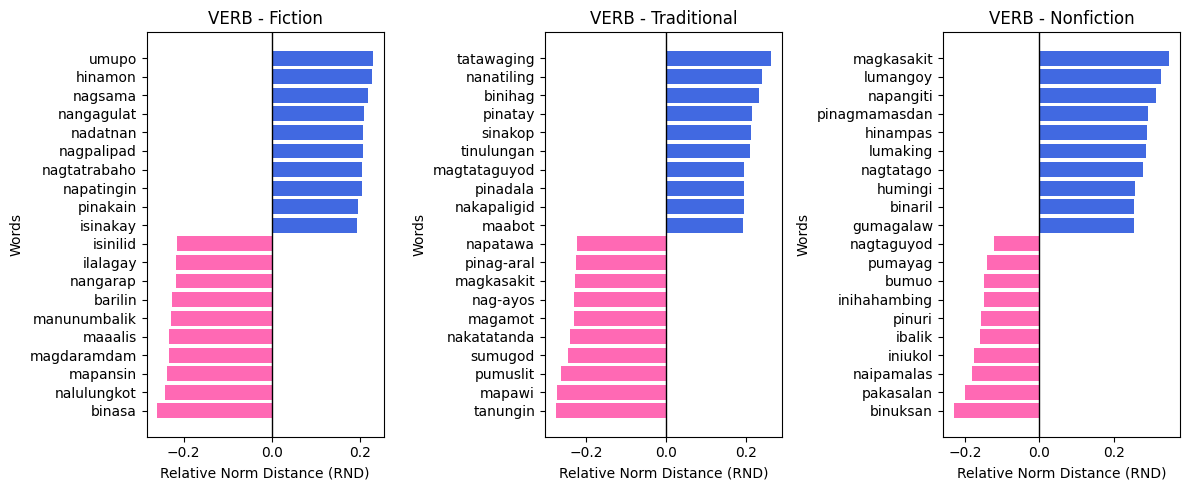

In [96]:
plot_rnd_pos(rnd_list, 'VERB', 10)

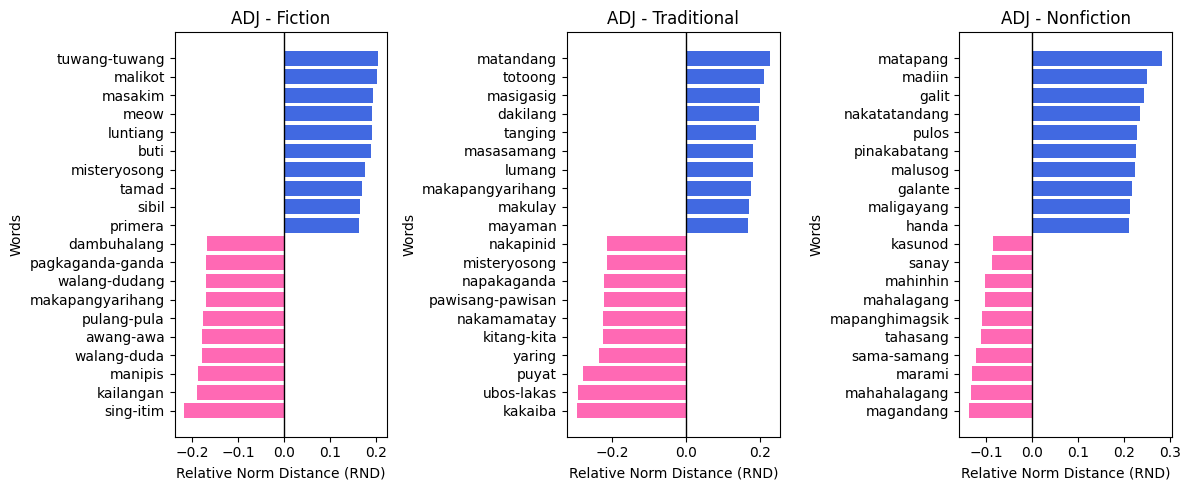

In [97]:
plot_rnd_pos(rnd_list, 'ADJ', 10)

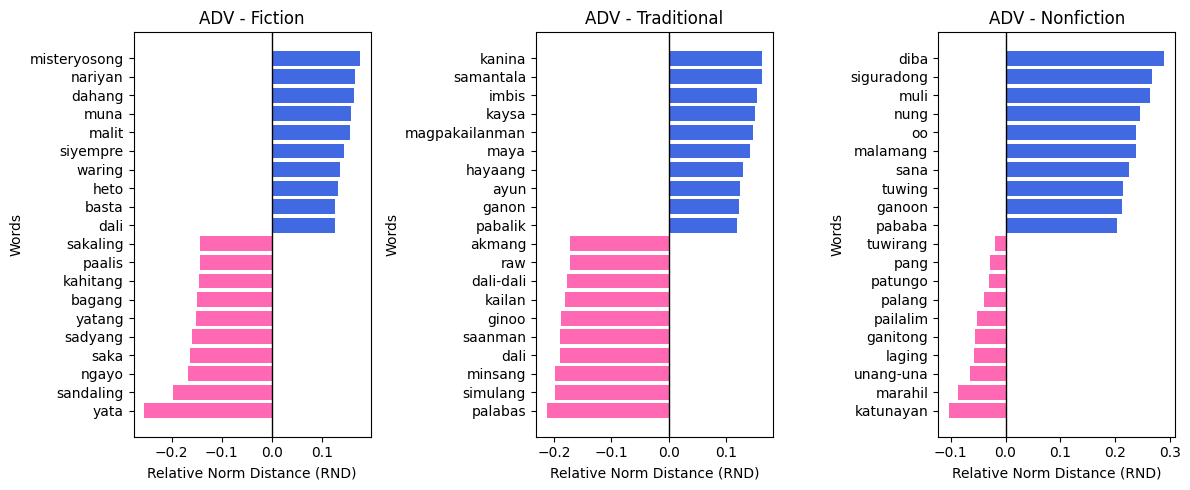

In [98]:
plot_rnd_pos(rnd_list, 'ADV', 10)

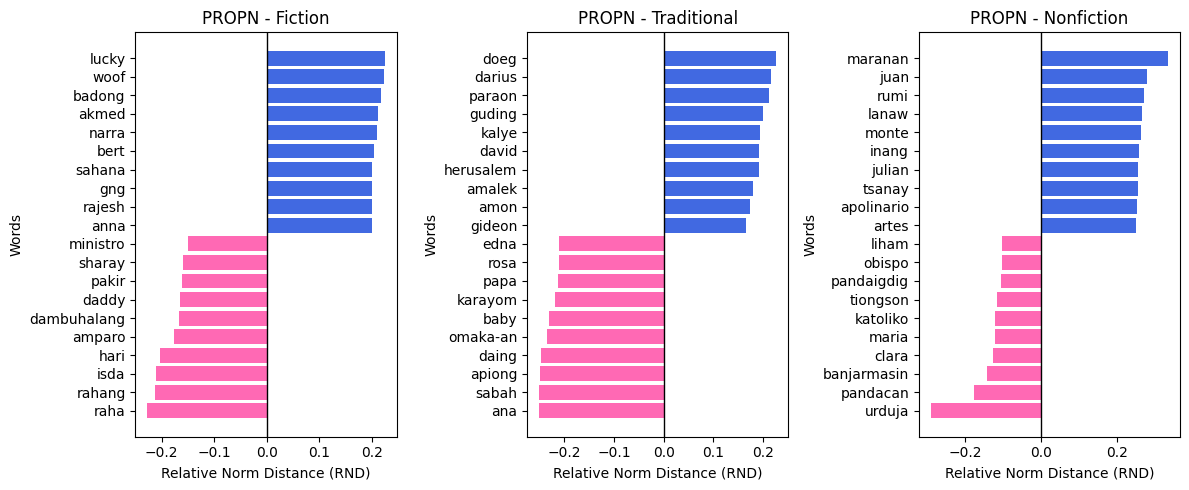

In [99]:
plot_rnd_pos(rnd_list, 'PROPN', 10)

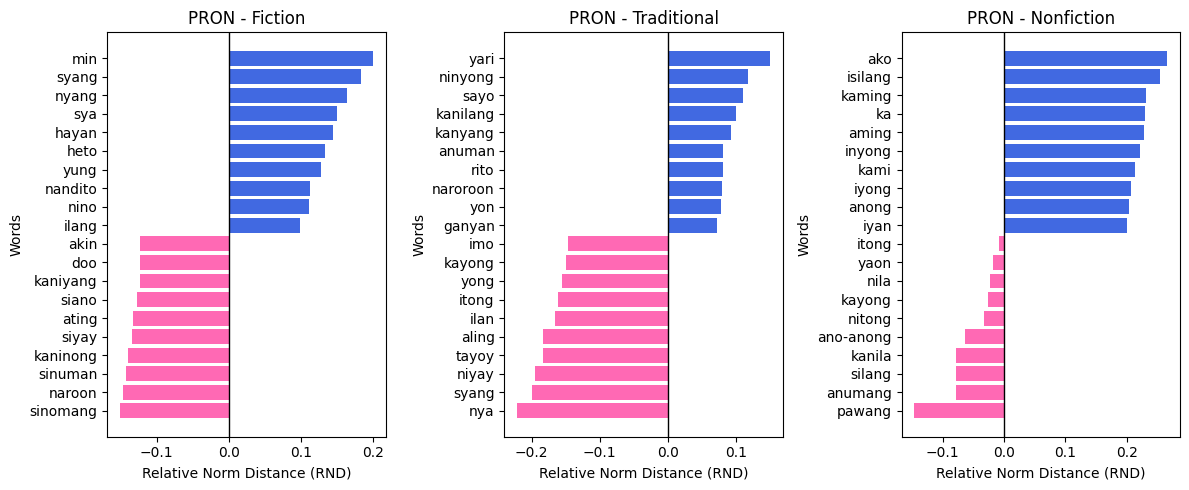

In [100]:
plot_rnd_pos(rnd_list, 'PRON', 10)

# WEAT implementation

### Load Themed data

In [25]:
df_fiction_themes = pd.read_csv('./weat-themes/WEAT Themes - fiction.csv')
df_traditional_themes = pd.read_csv('./weat-themes/WEAT Themes - traditional.csv')
df_nonfiction_themes = pd.read_csv('./weat-themes/WEAT Themes - creative nonfiction.csv')

In [132]:
df_fiction_themes['common theme'].value_counts()

common theme
other                                  40
Nature and Living Things               32
Place/ location/ direction/ country    25
People/ Name/ Person/ Identity         25
Quality/ Characteristics               23
Action/ Movement                       23
time                                   23
Emotion/ desire                        19
Quantity/ size/ measurement            17
Communication/ language                16
Parts of the Body                      12
Direction / Movement                   10
Object                                 10
family/ relationship/ community         9
comparison/ dfference                   7
possesion                               5
Emphasis                                4
limitation/ ahead                       2
Agreement                               1
Economic                                1
Religion and Spirituality               1
Name: count, dtype: int64

In [133]:
df_traditional_themes['common theme'].value_counts()

common theme
People/ Name/ Person/ Identity         40
Action/ Movement                       36
Nature and Living Things               29
Place/ location/ direction/ country    24
time                                   23
other                                  23
Quality/ Characteristics               18
Communication/ language                18
Emotion/ desire                        17
Quantity/ size/ measurement            15
family/ relationship/ community        12
Religion and Spirituality              11
Parts of the Body                       8
Object                                  7
comparison/ dfference                   7
limitation/ ahead                       6
Emphasis                                5
possesion                               2
Direction / Movement                    2
Agreement                               1
Economic                                1
Name: count, dtype: int64

In [134]:
df_nonfiction_themes['common theme'].value_counts()

common theme
People/ Name/ Person/ Identity         53
Action/ Movement                       38
Place/ location/ direction/ country    36
family/ relationship/ community        29
time                                   26
other                                  19
Quantity/ size/ measurement            16
Quality/ Characteristics               14
Social idea                            14
Object                                 10
Communication/ language                 9
comparison/ dfference                   7
Emotion/ desire                         7
Nature and Living Things                7
limitation/ ahead                       6
Religion and Spirituality               5
Emphasis                                3
possesion                               2
Economic                                2
Direction / Movement                    1
Parts of the Body                       1
Name: count, dtype: int64

## Recommended themes to use
### Fiction: 
    Family/ relationship/ community
    action/ movement
    quality/ characteristics
    emotion/ desire
    people/ name/ person/ identity
    communication/ language

### Traditional
    Family/ relationship/ community
    action/ movement
    quality/ characteristics
    emotion/ desire
    people/ name/ person/ identity
    Religion and Spirituality

### Nonfiction
    Family/ relationship/ community
    action/ movement
    quality/ characteristics
    emotion/ desire
    people/ name/ person/ identity
    Social Idea

In [26]:
fiction_family = df_fiction_themes[df_fiction_themes['common theme'] == 'family/ relationship/ community']['word'].to_list()
fiction_action = df_fiction_themes[df_fiction_themes['common theme'] == 'Action/ Movement']['word'].to_list()
fiction_quality = df_fiction_themes[df_fiction_themes['common theme'] == 'Quality/ Characteristics']['word'].to_list()
fiction_people = df_fiction_themes[df_fiction_themes['common theme'] == 'People/ Name/ Person/ Identity']['word'].to_list()
fiction_emotion = df_fiction_themes[df_fiction_themes['common theme'] == 'Emotion/ desire']['word'].to_list()
fiction_communication = df_fiction_themes[df_fiction_themes['common theme'] == 'Communication/ language']['word'].to_list()

traditional_family = df_traditional_themes[df_traditional_themes['common theme'] == 'family/ relationship/ community']['word'].to_list()
traditional_action = df_traditional_themes[df_traditional_themes['common theme'] == 'Action/ Movement']['word'].to_list()
traditional_quality = df_traditional_themes[df_traditional_themes['common theme'] == 'Quality/ Characteristics']['word'].to_list()
traditional_people = df_traditional_themes[df_traditional_themes['common theme'] == 'People/ Name/ Person/ Identity']['word'].to_list()
traditional_emotion = df_traditional_themes[df_traditional_themes['common theme'] == 'Emotion/ desire']['word'].to_list()
traditional_religion = df_traditional_themes[df_traditional_themes['common theme'] == 'Religion and Spirituality']['word'].to_list()

nonfiction_family = df_fiction_themes[df_fiction_themes['common theme'] == 'family/ relationship/ community']['word'].to_list()
nonfiction_action = df_fiction_themes[df_fiction_themes['common theme'] == 'Action/ Movement']['word'].to_list()
nonfiction_quality = df_fiction_themes[df_fiction_themes['common theme'] == 'Quality/ Characteristics']['word'].to_list()
nonfiction_people = df_fiction_themes[df_fiction_themes['common theme'] == 'People/ Name/ Person/ Identity']['word'].to_list()
nonfiction_emotion = df_fiction_themes[df_fiction_themes['common theme'] == 'Emotion/ desire']['word'].to_list()
nonfiction_social = df_fiction_themes[df_fiction_themes['common theme'] == 'Social idea']['word'].to_list()

fiction_themes = [fiction_family, fiction_action, fiction_quality, fiction_people, fiction_emotion, fiction_communication]
fiction_themes_label = ['family', 'action', 'quality', 'people', 'emotion', 'communication']
traditional_themes = [traditional_family, traditional_action, traditional_quality, traditional_people, traditional_emotion, traditional_religion]
traditional_themes_label = ['family', 'action', 'quality', 'people', 'emotion', 'religion']
nonfiction_themes = [nonfiction_family, nonfiction_action, nonfiction_quality, nonfiction_people, nonfiction_emotion]#, nonfiction_social]
nonfiction_themes_label = ['family', 'action', 'quality', 'people', 'emotion']#, 'social idea']

In [ ]:
from numpy.linalg import norm

def cosine_similarity_func(v1, v2):
    similarity = np.dot(v1, v2) / (norm(v1) * norm(v2))
    return similarity

# WEAT computation

# X/Y: themed target word sets
# A/B: gendered words
def WEAT(model, X, Y, A, B, n_permutations=1000):
    def weat_score(w, A, B):
        # cosine similarity based association
        # organizes cosine similarities into a testable structure
        return np.mean([cosine_similarity_func(model.wv[w], model.wv[a]) for a in A if a in model.wv]) - np.mean([cosine_similarity_func(model.wv[w], model.wv[b]) for b in B if b in model.wv])
    
    s_X = [weat_score(x, A, B) for x in X if x in model.wv]
    s_Y = [weat_score(y, A, B) for y in Y if y in model.wv]

    a_in_model = [a for a in A if a in model.wv]
    b_in_model = [b for b in B if b in model.wv]
    # effect size computation
    # measures how distinct the two target sets are
    effect_size = (np.mean(s_X) - np.mean(s_Y)) / np.std(s_X + s_Y)
    
    combined = X + Y
    # observed test statistic
    obs = np.abs(np.mean(s_X) - np.mean(s_Y))
    greater = 0
    for _ in range(n_permutations):
        np.random.shuffle(combined)
        Xp = combined[:len(X)]
        Yp = combined[len(X):]
        s_Xp = [weat_score(x, A, B) for x in Xp if x in model.wv]
        s_Yp = [weat_score(y, A, B) for y in Yp if y in model.wv]
        perm_diff = np.abs(np.mean(s_Xp) - np.mean(s_Yp))
        if perm_diff >= obs:
            greater += 1
    p_value = greater / n_permutations
    
    return effect_size, p_value, a_in_model, b_in_model


## Standard WEAT

In [138]:
genre_models = {
    "fiction": {
        "model": model_fiction_100,
        "targets": [
            [fiction_family, fiction_action], 
            [fiction_quality, fiction_action],
            [fiction_quality, fiction_emotion],
            [fiction_family, fiction_emotion]
        ],
        "targets label": ['family - action', 'quality - action', 'quality - emotion', 'family - emotion'],
        "male": fil_directly_male + corr_male_fiction_100,
        "female": fil_directly_female + corr_female_fiction_100
    },
    "traditional": {
        "model": model_traditional_100,
        "targets": [
            [traditional_family, traditional_action], 
            [traditional_quality, traditional_action],
            [traditional_quality, traditional_emotion],
            [traditional_family, traditional_emotion]
        ],
        "targets label": ['family - action', 'quality - action', 'quality - emotion', 'family - emotion'],
        "male": fil_directly_male + corr_male_traditional_100,
        "female": fil_directly_female + corr_female_traditional_100
    },
    "nonfiction": {
        "model": model_nonfiction_100,
        "targets": [
            [nonfiction_family, nonfiction_action], 
            [nonfiction_quality, nonfiction_action],
            [nonfiction_quality, nonfiction_emotion],
            [nonfiction_family, nonfiction_emotion]
        ],
        "targets label": ['family - action', 'quality - action', 'quality - emotion', 'family - emotion'],
        "male": fil_directly_male + corr_male_nonfiction_100,
        "female": fil_directly_female + corr_female_nonfiction_100
    },
}

weat_results = []

for genre, model in genre_models.items():

    print(f"Processing {genre}...")

    for targets, label in zip(model['targets'], model['targets label']):
        effect, p, male_words, female_words = WEAT(
            model["model"],
            targets[0],
            targets[1],
            model["male"],
            model["female"],
            n_permutations=10000
        )

        weat_results.append({
            "genre": genre,
            "comparison": label,
            "effect_size": effect,
            "p_value": p
        })
        
        print(f"Theme: {label}")
        print("Words target 1: ", targets[0][:10])
        print("Words target 2: ", targets[1][:10])
        print("Male words: ", male_words)
        print("Female words: ", female_words)
        print("Effect size:", effect)
        print("P-value:", p)

weat_res_df = pd.DataFrame(weat_results)

Processing fiction...
Theme: family - action
Words target 1:  ['anak', 'kaibigan', 'asawa', 'kasama', 'kapatid', 'magulang', 'tahanan', 'sabay', 'pamilya']
Words target 2:  ['nakita', 'makita', 'gawin', 'ginawa', 'nakikita', 'tingnan', 'tumakbo', 'umalis', 'gagawin', 'dala']
Male words:  ['lalaki', 'lalaking', 'kalalakihan', 'binata', 'binatang', 'ginoo', 'ingkong', 'kuya', 'lolo', 'monghe', 'tandang', 'tatay', 'tito', 'tiyuhin', 'itay', 'kapitan', 'kapitang', 'karterong', 'prinsipado', 'ginoong', 'papa']
Female words:  ['babae', 'babaeng', 'kababaihan', 'babaing', 'kababaihan', 'makababae', 'ate', 'binibini', 'binibining', 'impo', 'inang', 'inahin', 'dalaga', 'lola', 'prinsesa', 'reyna', 'sirena', 'dalagang', 'tiya', 'inay', 'prinsesang', 'maglola', 'maybahay', 'mongha', 'diwatang', 'engkantadang', 'rane', 'maestra']
Effect size: -0.14017121
P-value: 0.7348
Theme: quality - action
Words target 1:  ['kaya', 'bata', 'alam', 'bago', 'ginto', 'magandang', 'kulay', 'mabuti', 'malakas', 'di

In [139]:
weat_res_df

,genre,comparison,effect_size,p_value
0,fiction,family - action,-0.140171,0.7348
1,fiction,quality - action,-0.812490,0.0057
2,fiction,quality - emotion,-0.105111,0.7425
3,fiction,family - emotion,0.479291,0.2474
4,traditional,family - action,-0.193982,0.5661
5,traditional,quality - action,-0.047034,0.8719
6,traditional,quality - emotion,0.298514,0.3921
7,traditional,family - emotion,0.194804,0.6193
8,nonfiction,family - action,0.789214,0.0528
9,nonfiction,quality - action,0.205619,0.5214


### Visualize WEAT results

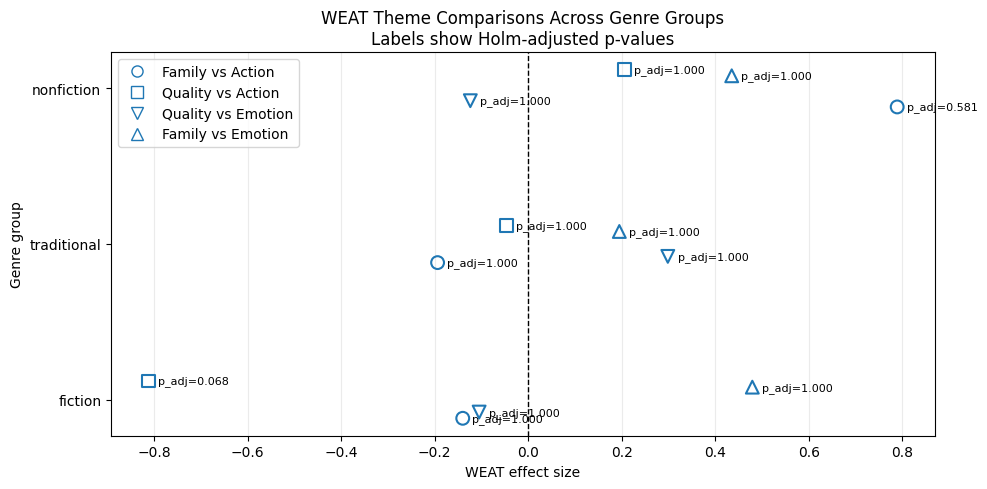

      genre        comparison  effect_size  p_value  P_Holm
    fiction   family - action      -0.1402   0.7348  1.0000
    fiction  quality - action      -0.8125   0.0057  0.0684
    fiction quality - emotion      -0.1051   0.7425  1.0000
    fiction  family - emotion       0.4793   0.2474  1.0000
traditional   family - action      -0.1940   0.5661  1.0000
traditional  quality - action      -0.0470   0.8719  1.0000
traditional quality - emotion       0.2985   0.3921  1.0000
traditional  family - emotion       0.1948   0.6193  1.0000
 nonfiction   family - action       0.7892   0.0528  0.5808
 nonfiction  quality - action       0.2056   0.5214  1.0000
 nonfiction quality - emotion      -0.1240   0.7107  1.0000
 nonfiction  family - emotion       0.4352   0.3212  1.0000


In [ ]:
from statsmodels.stats.multitest import multipletests

# Holm adjustment across the six WEAT tests
weat_res_df["P_Holm"] = multipletests(
    weat_res_df["p_value"],
    method="holm"
)[1]

fig, ax = plt.subplots(figsize=(10, 5))

genre_positions = {
    "fiction": 0,
    "traditional": 1,
    "nonfiction": 2,
}

offsets = {
    "family - action": -0.12,
    "quality - action": 0.12,
    "quality - emotion": -0.08,
    "family - emotion": 0.08
}

markers = {
    "family - action": "o",
    "quality - action": "s",
    "quality - emotion": "v",
    "family - emotion": "^"
}

for _, row in weat_res_df.iterrows():
    y = (
        genre_positions[row["genre"]]
        + offsets[row["comparison"]]
    )

    significant = row["P_Holm"] < 0.05

    ax.scatter(
        row["effect_size"],
        y,
        s=85,
        marker=markers[row["comparison"]],
        facecolors="C0" if significant else "none",
        edgecolors="C0",
        linewidths=1.5,
        label=row["comparison"],
        zorder=3
    )

    ax.annotate(
        f"p_adj={row['P_Holm']:.3f}",
        (row["effect_size"], y),
        xytext=(7, 0),
        textcoords="offset points",
        va="center",
        fontsize=8
    )

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(list(genre_positions.values()))
ax.set_yticklabels(list(genre_positions.keys()))
ax.set_xlabel("WEAT effect size")
ax.set_ylabel("Genre group")
ax.set_title(
    "WEAT Theme Comparisons Across Genre Groups\n"
    "Labels show Holm-adjusted p-values"
)
ax.grid(axis="x", alpha=0.25)

# Create a clean legend with one entry per comparison
from matplotlib.lines import Line2D

legend_items = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="none",
        markerfacecolor="none",
        markeredgecolor="C0",
        markersize=8,
        label="Family vs Action"
    ),
    Line2D(
        [0], [0],
        marker="s",
        linestyle="none",
        markerfacecolor="none",
        markeredgecolor="C0",
        markersize=8,
        label="Quality vs Action"
    ),
    Line2D(
        [0], [0],
        marker="v",
        linestyle="none",
        markerfacecolor="none",
        markeredgecolor="C0",
        markersize=8,
        label="Quality vs Emotion"
    ),
    Line2D(
        [0], [0],
        marker="^",
        linestyle="none",
        markerfacecolor="none",
        markeredgecolor="C0",
        markersize=8,
        label="Family vs Emotion"
    ),
]

ax.legend(handles=legend_items, loc="best")
plt.tight_layout()
plt.savefig("weat_effect_sizes.png", dpi=300, bbox_inches="tight")
plt.show()

print(
    weat_res_df[
        ["genre", "comparison", "effect_size", "p_value", "P_Holm"]
    ].round(4).to_string(index=False)
)

In [204]:
weat_res_df.round(4)

,genre,comparison,effect_size,p_value,P_Holm
0,fiction,family - action,-0.1402,0.7348,1.0000
1,fiction,quality - action,-0.8125,0.0057,0.0684
2,fiction,quality - emotion,-0.1051,0.7425,1.0000
3,fiction,family - emotion,0.4793,0.2474,1.0000
4,traditional,family - action,-0.1940,0.5661,1.0000
5,traditional,quality - action,-0.0470,0.8719,1.0000
6,traditional,quality - emotion,0.2985,0.3921,1.0000
7,traditional,family - emotion,0.1948,0.6193,1.0000
8,nonfiction,family - action,0.7892,0.0528,0.5808
9,nonfiction,quality - action,0.2056,0.5214,1.0000


In [208]:
weat_res_df.to_csv('weat_res.csv')

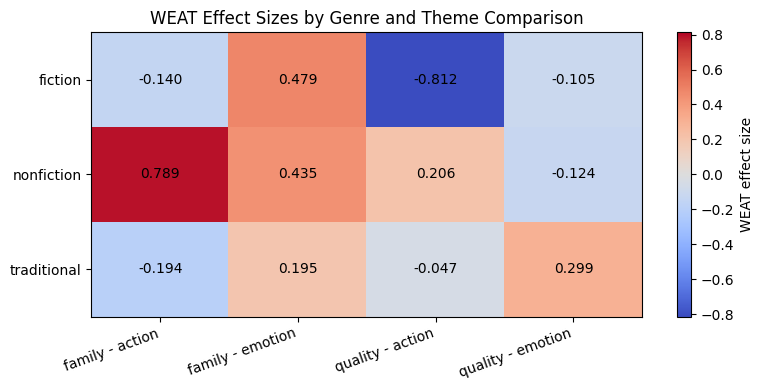

In [144]:

heatmap_data = weat_res_df.pivot(
    index="genre",
    columns="comparison",
    values="effect_size"
)

fig, ax = plt.subplots(figsize=(8, 4))

im = ax.imshow(
    heatmap_data.values,
    aspect="auto",
    cmap="coolwarm",
    vmin=-max(abs(heatmap_data.values.min()),
              abs(heatmap_data.values.max())),
    vmax=max(abs(heatmap_data.values.min()),
              abs(heatmap_data.values.max()))
)

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns, rotation=20, ha="right")
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        value = heatmap_data.iloc[i, j]
        ax.text(j, i, f"{value:.3f}", ha="center", va="center")

fig.colorbar(im, ax=ax, label="WEAT effect size")
ax.set_title("WEAT Effect Sizes by Genre and Theme Comparison")
plt.tight_layout()
plt.savefig("weat_effect_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


# SEAT and BERT Implementation

In [15]:
df_all = pd.read_csv('./txt-files/clean_all_corpus_agg.txt', header=None, names=['sentence'])
df_fiction = pd.read_csv('./txt-files/clean_fiction_agg.txt', header=None, names=['sentence'])
df_traditional = pd.read_csv('./txt-files/clean_traditional_agg.txt', header=None, names=['sentence'])
df_nonfiction = pd.read_csv('./txt-files/clean_nonfiction_agg.txt', header=None, names=['sentence'])

In [18]:
male_fiction_seed = fil_directly_male + corr_male_fiction
female_fiction_seed = fil_directly_female + corr_female_fiction

male_trad_seed = fil_directly_male + corr_male_traditional
female_traditional_seed = fil_directly_female + corr_female_traditional

male_nonfiction_seed = fil_directly_male + corr_male_nonfiction
female_nonfiction_seed = fil_directly_female + corr_female_nonfiction

NameError: name 'corr_male_fiction' is not defined

In [19]:
male_seeds = fil_directly_male + fil_male_marked
female_seeds = fil_directly_female + fil_female_marked

### Detect sentences with gendred seed words

In [20]:
def contains_seed(sentence, seeds):
    words = re.findall(r'\b\w+\b', sentence.lower())
    return any(word in seeds for word in words)

In [21]:
df_all["contains_male_seed"] = df_all["sentence"].apply(
    lambda x: contains_seed(x, male_seeds)
)

df_all["contains_female_seed"] = df_all["sentence"].apply(
    lambda x: contains_seed(x, female_seeds)
)

df_fiction["contains_male_seed"] = df_fiction["sentence"].apply(
    lambda x: contains_seed(x, male_seeds)
)

df_fiction["contains_female_seed"] = df_fiction["sentence"].apply(
    lambda x: contains_seed(x, female_seeds)
)

df_traditional["contains_male_seed"] = df_traditional["sentence"].apply(
    lambda x: contains_seed(x, male_seeds)
)

df_traditional["contains_female_seed"] = df_traditional["sentence"].apply(
    lambda x: contains_seed(x, female_seeds)
)

df_nonfiction["contains_male_seed"] = df_nonfiction["sentence"].apply(
    lambda x: contains_seed(x, male_seeds)
)

df_nonfiction["contains_female_seed"] = df_nonfiction["sentence"].apply(
    lambda x: contains_seed(x, female_seeds)
)

In [22]:
df_fiction

,sentence,contains_male_seed,contains_female_seed
0,parehong pilipino ang mga magulang ni juan per...,False,False
1,nagtatrabaho bilang software engineer ang mama...,True,True
2,pareho silang nagtatrabaho sa london,False,False
3,madalas siyang kwentuhan ng kanyang mga magula...,False,False
4,pero ni minsan ay di pa nakatungtong si juan s...,False,False
...,...,...,...
17008,ginagamit na pansindi ng kalan at pansiga ng b...,False,False
17009,ginagamit sa paglilitson at pag_ihaw ginagamit...,False,False
17010,samantala ang tatay ni munting ningas_apoy ay ...,True,False
17011,kaya naman kahit na malit dapat pasalamatan si...,False,False


In [23]:
df_all["gender_type"] = "none"

df_all.loc[
    df_all["contains_male_seed"] & ~df_all["contains_female_seed"],
    "gender_type"
] = "male"

df_all.loc[
    df_all["contains_female_seed"] & ~df_all["contains_male_seed"],
    "gender_type"
] = "female"

df_all.loc[
    df_all["contains_male_seed"] & df_all["contains_female_seed"],
    "gender_type"
] = "both"

df_fiction["gender_type"] = "none"

df_fiction.loc[
    df_fiction["contains_male_seed"] & ~df_fiction["contains_female_seed"],
    "gender_type"
] = "male"

df_fiction.loc[
    df_fiction["contains_female_seed"] & ~df_fiction["contains_male_seed"],
    "gender_type"
] = "female"

df_fiction.loc[
    df_fiction["contains_male_seed"] & df_fiction["contains_female_seed"],
    "gender_type"
] = "both"

df_traditional["gender_type"] = "none"

df_traditional.loc[
    df_traditional["contains_male_seed"] & ~df_traditional["contains_female_seed"],
    "gender_type"
] = "male"

df_traditional.loc[
    df_traditional["contains_female_seed"] & ~df_traditional["contains_male_seed"],
    "gender_type"
] = "female"

df_traditional.loc[
    df_traditional["contains_male_seed"] & df_traditional["contains_female_seed"],
    "gender_type"
] = "both"

df_nonfiction["gender_type"] = "none"

df_nonfiction.loc[
    df_nonfiction["contains_male_seed"] & ~df_nonfiction["contains_female_seed"],
    "gender_type"
] = "male"

df_nonfiction.loc[
    df_nonfiction["contains_female_seed"] & ~df_nonfiction["contains_male_seed"],
    "gender_type"
] = "female"

df_nonfiction.loc[
    df_nonfiction["contains_male_seed"] & df_nonfiction["contains_female_seed"],
    "gender_type"
] = "both"

In [27]:
fiction_themes_dict = {
    "family": fiction_family, 
    "action": fiction_action, 
    "quality": fiction_quality, 
    "people": fiction_people, 
    "emotion": fiction_emotion, 
    "communication": fiction_communication
}

traditional_themes_dict = {
    "family": traditional_family, 
    "action": traditional_action, 
    "quality": traditional_quality, 
    "people":  traditional_people, 
    "emotion": traditional_emotion, 
    "religion": traditional_religion
}

nonfiction_themes_dict = {
    "family": nonfiction_family, 
    "action": nonfiction_action, 
    "quality": nonfiction_quality, 
    "people": nonfiction_people, 
    "emotion": nonfiction_emotion, 
    "social": nonfiction_social
}


### Setup dfs without containing gendered seed words

In [28]:
theme_df_fiction = df_fiction[
    (df_fiction["gender_type"] == "none")
].copy()

theme_df_traditional = df_traditional[
    (df_traditional["gender_type"] == "none")
].copy()

theme_df_nonfiction = df_nonfiction[
    (df_nonfiction["gender_type"] == "none")
].copy()

In [29]:
theme_df_fiction

,sentence,contains_male_seed,contains_female_seed,gender_type
0,parehong pilipino ang mga magulang ni juan per...,False,False,none
2,pareho silang nagtatrabaho sa london,False,False,none
3,madalas siyang kwentuhan ng kanyang mga magula...,False,False,none
4,pero ni minsan ay di pa nakatungtong si juan s...,False,False,none
5,hanggang ngayon,False,False,none
...,...,...,...,...
17005,pansunog sila sa mga sukal para may pagtamnan ...,False,False,none
17008,ginagamit na pansindi ng kalan at pansiga ng b...,False,False,none
17009,ginagamit sa paglilitson at pag_ihaw ginagamit...,False,False,none
17011,kaya naman kahit na malit dapat pasalamatan si...,False,False,none


In [30]:
def find_theme_sentences(df, theme_words, text_col="sentence"):
    results = []

    for theme, words in theme_words.items():
        words = sorted(
            set(w.lower() for w in words),
            key=len,
            reverse=True
        )

        if not words:
            continue

        # Match whole words, case-insensitively
        pattern = (
            r"(?<!\w)(?:"
            + "|".join(re.escape(w) for w in words)
            + r")(?!\w)"
        )

        sentences = df[text_col].fillna("").astype(str)
        mask = sentences.str.contains(pattern, case=False, regex=True)

        for idx, sentence in sentences.loc[mask].items():
            matched_words = [
                word for word in words
                if re.search(
                    r"(?<!\w)" + re.escape(word) + r"(?!\w)",
                    sentence,
                    flags=re.IGNORECASE
                )
            ]

            results.append({
                "row_id": idx,
                "theme": theme,
                "matched_words": matched_words,
                "sentence": sentence
            })

    return pd.DataFrame(
        results,
        columns=["row_id", "theme", "matched_words", "sentence"]
    )

### Get sentences with themed words

In [31]:
# Run separately for each genre group
sentences_fiction = find_theme_sentences(
    theme_df_fiction, fiction_themes_dict, text_col="sentence"
)

sentences_traditional = find_theme_sentences(
    theme_df_traditional, traditional_themes_dict, text_col="sentence"
)

sentences_nonfiction = find_theme_sentences(
    theme_df_nonfiction, nonfiction_themes_dict, text_col="sentence"
)

In [32]:
all_theme_sentences = pd.concat(
    [
        sentences_fiction.assign(genre_group="Fiction"),
        sentences_traditional.assign(genre_group="Traditional"),
        sentences_nonfiction.assign(genre_group="Nonfiction")
    ],
    ignore_index=True
)

In [33]:
sentences_fiction

,row_id,theme,matched_words,sentence
0,0,family,[magulang],parehong pilipino ang mga magulang ni juan per...
1,3,family,[magulang],madalas siyang kwentuhan ng kanyang mga magula...
2,45,family,[asawa],si gregoria de jesus ang asawa ni andres bonif...
3,70,family,[magulang],pilipino ka ba dahil ang mga magulang mo ay pi...
4,72,family,[pamilya],ang pagka_pilipino ba ay makikita sa pagiging ...
...,...,...,...,...
8821,16870,communication,[sabi],sabi ni ason may nasira sa raketsip nila kaya ...
8822,16874,communication,[sabi],gusto kong makita ang inyong planeta sabi pa n...
8823,16911,communication,[sabi],sumakay ka at bumalik sa iyong planeta sabi ni...
8824,16951,communication,[sagot],opo sagot ng bata


In [34]:
sentences_traditional

,row_id,theme,matched_words,sentence
0,34,family,[lider],mataba mapayat mga bibe ngunit ang may pakpak ...
1,37,family,[lider],ngunit ang may pakpak sa likod ay iisa siya an...
2,39,family,[lider],siya ang lider na nagsabi ng kwak kwak
3,41,family,[lider],mataba mapayat mga bibe ngunit ang may pakpak ...
4,47,family,[magulang],tanong ko sa mga magulang ko
...,...,...,...,...
5960,7947,religion,[bathala],lingid sa kaalaman ni kawayan nakarating kay b...
5961,7948,religion,[bathala],bilang parusa ang laging nakatingalang si kawa...
5962,7949,religion,[bathala],ang pagyuko ni kawayan ay pagbibigay halaga na...
5963,8020,religion,[diyos],ngunit humingi ka ng tawad sa diyos


In [35]:
sentences_nonfiction

,row_id,theme,matched_words,sentence
0,6,family,[pamilya],binartolina ako nang maraming buwan at sa buon...
1,7,family,"[magulang, anak]",ang mga anak namin ang pinakanaghirap dahil na...
2,8,family,[anak],noong nililitis ako sa kasong hindi naman umuu...
3,9,family,[anak],inamin nila na inaresto nila ang anak ko at di...
4,11,family,[anak],hanggang ngayon hindi ko pa nakikita ang anak ko
...,...,...,...,...
1145,3511,emotion,[dahilan],ang kapansanan ay di dapat maging dahilan upan...
1146,3524,emotion,[masaya],karapatan mong maging masaya at malaya makipag...
1147,3532,emotion,"[tunay, totoo]",pag_ibahin ang tunay mula sa hindi totoo
1148,3533,emotion,[tunay],alin ang tunay


In [36]:
sentences_fiction['theme'].unique()

array(['family', 'action', 'quality', 'people', 'emotion',
       'communication'], dtype=object)

In [37]:
sentences_traditional['theme'].unique()

array(['family', 'action', 'quality', 'people', 'emotion', 'religion'],
      dtype=object)

In [38]:
sentences_nonfiction['theme'].unique()

array(['family', 'action', 'quality', 'people', 'emotion'], dtype=object)

In [39]:
s_fiction_family = sentences_fiction[sentences_fiction['theme'] == 'family']['sentence'].tolist()
s_fiction_action = sentences_fiction[sentences_fiction['theme'] == 'action']['sentence'].tolist()
s_fiction_quality = sentences_fiction[sentences_fiction['theme'] == 'quality']['sentence'].tolist()
s_fiction_people = sentences_fiction[sentences_fiction['theme'] == 'people']['sentence'].tolist()
s_fiction_emotion = sentences_fiction[sentences_fiction['theme'] == 'emotion']['sentence'].tolist()
s_fiction_communication = sentences_fiction[sentences_fiction['theme'] == 'communication']['sentence'].tolist()

s_traditional_family = sentences_traditional[sentences_traditional['theme'] == 'family']['sentence'].tolist()
s_traditional_action = sentences_traditional[sentences_traditional['theme'] == 'action']['sentence'].tolist()
s_traditional_quality = sentences_traditional[sentences_traditional['theme'] == 'quality']['sentence'].tolist()
s_traditional_people = sentences_traditional[sentences_traditional['theme'] == 'people']['sentence'].tolist()
s_traditional_emotion = sentences_traditional[sentences_traditional['theme'] == 'emotion']['sentence'].tolist()
s_traditional_religion = sentences_traditional[sentences_traditional['theme'] == 'religion']['sentence'].tolist()

s_nonfiction_family = sentences_nonfiction[sentences_nonfiction['theme'] == 'family']['sentence'].tolist()
s_nonfiction_action = sentences_nonfiction[sentences_nonfiction['theme'] == 'action']['sentence'].tolist()
s_nonfiction_quality = sentences_nonfiction[sentences_nonfiction['theme'] == 'quality']['sentence'].tolist()
s_nonfiction_people = sentences_nonfiction[sentences_nonfiction['theme'] == 'people']['sentence'].tolist()
s_nonfiction_emotion = sentences_nonfiction[sentences_nonfiction['theme'] == 'emotion']['sentence'].tolist()

### Encode Sentences with BERT

In [165]:
from transformers import AutoTokenizer, AutoModel
import torch
import numpy as np

/opt/anaconda3/envs/nlp_env/lib/python3.11/site-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


In [166]:
MODEL_NAME = "bert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME)
model.eval()

/opt/anaconda3/envs/nlp_env/lib/python3.11/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/opt/anaconda3/envs/nlp_env/lib/python3.11/site-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(119547, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
            (dropout): Dropout(p=0.1, inplace=False)
 

#### Convert each sentence into a vector

mean pooling

In [167]:
def mean_pooling(model_output, attention_mask):

    token_embeddings = model_output.last_hidden_state

    input_mask_expanded = (
        attention_mask
        .unsqueeze(-1)
        .expand(token_embeddings.size())
        .float()
    )

    return torch.sum(
        token_embeddings * input_mask_expanded,
        dim=1
    ) / torch.clamp(
        input_mask_expanded.sum(dim=1),
        min=1e-9
    )

@torch.no_grad()
def encode_sentences(sentences, batch_size=32):

    embeddings = []

    for i in range(0, len(sentences), batch_size):

        batch = sentences[i:i + batch_size]

        encoded = tokenizer(
            batch,
            padding=True,
            truncation=True,
            return_tensors="pt"
        )

        output = model(**encoded)

        pooled = mean_pooling(
            output,
            encoded["attention_mask"]
        )

        embeddings.append(
            pooled.cpu().numpy()
        )

    return np.vstack(embeddings)

### Get gendered sentences

In [168]:
# Fiction
fiction_male_sentences = df_fiction[
    df_fiction["gender_type"] == "male"
]

fiction_female_sentences = df_fiction[
    df_fiction["gender_type"] == "female"
]

# Traditional
traditional_male_sentences = df_traditional[
    df_traditional["gender_type"] == "male"
]

traditional_female_sentences = df_traditional[
    df_traditional["gender_type"] == "female"
]

# Nonfiction
nonfiction_male_sentences = df_nonfiction[
    df_nonfiction["gender_type"] == "male"
]

nonfiction_female_sentences = df_nonfiction[
    df_nonfiction["gender_type"] == "female"
]

### Only sentence text

In [169]:
fiction_male_text = fiction_male_sentences["sentence"].tolist()
fiction_female_text = fiction_female_sentences["sentence"].tolist()

traditional_male_text = traditional_male_sentences["sentence"].tolist()
traditional_female_text = traditional_female_sentences["sentence"].tolist()

nonfiction_male_text = nonfiction_male_sentences["sentence"].tolist()
nonfiction_female_text = nonfiction_female_sentences["sentence"].tolist()

### Number of sentences in each genre group

In [170]:
for name, df in {
    "Fiction": df_fiction,
    "Traditional": df_traditional,
    "Nonfiction": df_nonfiction
}.items():
    print(f"\n{name}")
    print(df["gender_type"].value_counts())


Fiction
gender_type
none      13449
male       1771
female     1333
both        460
Name: count, dtype: int64

Traditional
gender_type
none      6769
male       792
female     419
both       132
Name: count, dtype: int64

Nonfiction
gender_type
none      3248
male       240
female     109
both        13
Name: count, dtype: int64


### Encode gendered sentences

## MORE EFFICIENT

In [171]:
import numpy as np
import pandas as pd
from pathlib import Path

# Organize theme sentences by genre group
theme_sentences = {
    "fiction": {
        "family": s_fiction_family,
        "action": s_fiction_action,
        "quality": s_fiction_quality,
        "people": s_fiction_people,
        "emotion": s_fiction_emotion,
        "communication": s_fiction_communication,
    },
    "traditional": {
        "family": s_traditional_family,
        "action": s_traditional_action,
        "quality": s_traditional_quality,
        "people": s_traditional_people,
        "emotion": s_traditional_emotion,
        "religion": s_traditional_religion,
    },
    "nonfiction": {
        "family": s_nonfiction_family,
        "action": s_nonfiction_action,
        "quality": s_nonfiction_quality,
        "people": s_nonfiction_people,
        "emotion": s_nonfiction_emotion,
    },
}

# Organize gender-associated sentences
gender_sentences = {
    "fiction": {
        "male": fiction_male_text,
        "female": fiction_female_text,
    },
    "traditional": {
        "male": traditional_male_text,
        "female": traditional_female_text,
    },
    "nonfiction": {
        "male": nonfiction_male_text,
        "female": nonfiction_female_text,
    },
}

# Encode all sentences
theme_vectors = {}
gender_vectors = {}

for genre, themes in theme_sentences.items():
    theme_vectors[genre] = {}

    for theme, sentences in themes.items():
        theme_vectors[genre][theme] = encode_sentences(sentences)

for genre, genders in gender_sentences.items():
    gender_vectors[genre] = {}

    for gender, sentences in genders.items():
        gender_vectors[genre][gender] = encode_sentences(sentences)

### Save embeddings

In [172]:
from pathlib import Path
import numpy as np

output_dir = Path("sentence_embeddings")
output_dir.mkdir(parents=True, exist_ok=True)

for genre, themes in theme_vectors.items():
    for theme, vectors in themes.items():
        np.save(
            output_dir / f"{genre}_{theme}_vec.npy",
            vectors
        )

for genre, genders in gender_vectors.items():
    for gender, vectors in genders.items():
        np.save(
            output_dir / f"{genre}_{gender}_vectors.npy",
            vectors
        )

### Load Embeddings

In [9]:
import numpy as np
from pathlib import Path

output_dir = Path("sentence_embeddings")

theme_vectors = {
    genre: {
        theme: np.load(output_dir / f"{genre}_{theme}_vec.npy")
        for theme in themes
    }
    for genre, themes in {
        "fiction": [
            "family", "action", "quality", "people",
            "emotion", "communication"
        ],
        "traditional": [
            "family", "action", "quality", "people",
            "emotion", "religion"
        ],
        "nonfiction": [
            "family", "action", "quality", "people", "emotion"
        ],
    }.items()
}

gender_vectors = {
    genre: {
        gender: np.load(
            output_dir / f"{genre}_{gender}_vectors.npy"
        )
        for gender in ["male", "female"]
    }
    for genre in ["fiction", "traditional", "nonfiction"]
}

### Verify the results

In [10]:
for genre, themes in theme_vectors.items():
    for theme, vectors in themes.items():
        print(f"{genre} | {theme}: {vectors.shape}")

for genre, genders in gender_vectors.items():
    for gender, vectors in genders.items():
        print(f"{genre} | {gender}: {vectors.shape}")

fiction | family: (821, 768)
fiction | action: (1410, 768)
fiction | quality: (1811, 768)
fiction | people: (1836, 768)
fiction | emotion: (1314, 768)
fiction | communication: (1635, 768)
traditional | family: (522, 768)
traditional | action: (1299, 768)
traditional | quality: (786, 768)
traditional | people: (1721, 768)
traditional | emotion: (564, 768)
traditional | religion: (1073, 768)
nonfiction | family: (180, 768)
nonfiction | action: (208, 768)
nonfiction | quality: (330, 768)
nonfiction | people: (265, 768)
nonfiction | emotion: (167, 768)
fiction | male: (1771, 768)
fiction | female: (1333, 768)
traditional | male: (792, 768)
traditional | female: (419, 768)
nonfiction | male: (240, 768)
nonfiction | female: (109, 768)


### Accessing each embedding

In [11]:
fiction_family_vec = theme_vectors["fiction"]["family"]
fiction_action_vec = theme_vectors["fiction"]["action"]
fiction_quality_vec = theme_vectors["fiction"]["quality"]
fiction_people_vec = theme_vectors["fiction"]["people"]
fiction_emotion_vec = theme_vectors["fiction"]["emotion"]
fiction_communication_vec = theme_vectors["fiction"]["communication"]

fiction_male_vectors = gender_vectors["fiction"]["male"]
fiction_female_vectors = gender_vectors["fiction"]["female"]

traditional_family_vec = theme_vectors["traditional"]["family"]
traditional_action_vec = theme_vectors["traditional"]["action"]
traditional_quality_vec = theme_vectors["traditional"]["quality"]
traditional_people_vec = theme_vectors["traditional"]["people"]
traditional_emotion_vec = theme_vectors["traditional"]["emotion"]
traditional_religion_vec = theme_vectors["traditional"]["religion"]

traditional_male_vectors = gender_vectors["traditional"]["male"]
traditional_female_vectors = gender_vectors["traditional"]["female"]

nonfiction_family_vec = theme_vectors["nonfiction"]["family"]
nonfiction_action_vec = theme_vectors["nonfiction"]["action"]
nonfiction_quality_vec = theme_vectors["nonfiction"]["quality"]
nonfiction_people_vec = theme_vectors["nonfiction"]["people"]
nonfiction_emotion_vec = theme_vectors["nonfiction"]["emotion"]

nonfiction_male_vectors = gender_vectors["nonfiction"]["male"]
nonfiction_female_vectors = gender_vectors["nonfiction"]["female"]

## Calculate Cosine and Mean assoc

In [12]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np

def association(w, A, B):

    sim_A = cosine_similarity(w.reshape(1, -1), A).mean()
    sim_B = cosine_similarity(w.reshape(1, -1), B).mean()

    return sim_A - sim_B

def mean_association(target_vectors, A, B):

    scores = []

    for w in target_vectors:
        scores.append(association(w, A, B))

    return np.mean(scores)

### Calculate Mean Assoc

In [13]:
# SEAT test targets: family-action, quality-action
fiction_family_assoc = mean_association(fiction_family_vec, fiction_male_vectors, fiction_female_vectors)
fiction_quality_assoc = mean_association(fiction_quality_vec, fiction_male_vectors, fiction_female_vectors)
fiction_action_assoc = mean_association(fiction_action_vec, fiction_male_vectors, fiction_female_vectors)

traditional_family_assoc = mean_association(traditional_family_vec, traditional_male_vectors, traditional_female_vectors)
traditional_quality_assoc = mean_association(traditional_quality_vec, traditional_male_vectors, traditional_female_vectors)
traditional_action_assoc = mean_association(traditional_action_vec, traditional_male_vectors, traditional_female_vectors)

nonfiction_family_assoc = mean_association(nonfiction_family_vec, nonfiction_male_vectors, nonfiction_female_vectors)
nonfiction_quality_assoc = mean_association(nonfiction_quality_vec, nonfiction_male_vectors, nonfiction_female_vectors)
nonfiction_action_assoc = mean_association(nonfiction_action_vec, nonfiction_male_vectors, nonfiction_female_vectors)

## Calculate SEAT Effect Size and Permutation Test

In [40]:
theme_sentences = {
    "fiction": {
        "family": s_fiction_family,
        "action": s_fiction_action,
        "quality": s_fiction_quality,
        "emotion": s_fiction_emotion,
    },
    "traditional": {
        "family": s_traditional_family,
        "action": s_traditional_action,
        "quality": s_traditional_quality,
        "emotion": s_traditional_emotion,
    },
    "creative nonfiction": {
        "family": s_nonfiction_family,
        "action": s_nonfiction_action,
        "quality": s_nonfiction_quality,
        "emotion": s_nonfiction_emotion,
    },
}

In [41]:
def association_scores(target_vectors, A, B):

    return np.array([
        association(w, A, B)
        for w in target_vectors
    ])

def seat_effect_size(X_scores, Y_scores):
    pooled_scores = np.concatenate([X_scores, Y_scores])
    denominator = np.std(pooled_scores, ddof=1)

    if denominator == 0:
        return np.nan

    return (X_scores.mean() - Y_scores.mean()) / denominator

def permutation_test(X_scores, Y_scores, n_permutations=10000, random_state=42):

    if len(X_scores) == 0 or len(Y_scores) == 0:
        return np.nan, np.nan

    observed = X_scores.mean() - Y_scores.mean()
    combined = np.concatenate([X_scores, Y_scores])
    n_X = len(X_scores)

    rng = np.random.default_rng(random_state)
    count = 0

    for _ in range(n_permutations):
        shuffled = rng.permutation(combined)
        difference = (
            shuffled[:n_X].mean() - shuffled[n_X:].mean()
        )

        if abs(difference) >= abs(observed):
            count += 1

    p_value = (count + 1) / (n_permutations + 1)

    return observed, p_value

In [42]:
# Theme embeddings by genre group
theme_vectors = {
    "fiction": {
        "family": fiction_family_vec,
        "action": fiction_action_vec,
        "quality": fiction_quality_vec,
        "emotion": fiction_emotion_vec
    },
    "traditional": {
        "family": traditional_family_vec,
        "action": traditional_action_vec,
        "quality": traditional_quality_vec,
        "emotion": traditional_emotion_vec
    },
    "creative nonfiction": {
        "family": nonfiction_family_vec,
        "action": nonfiction_action_vec,
        "quality": nonfiction_quality_vec,
        "emotion": nonfiction_emotion_vec
    },
}

# Gender-associated sentence embeddings by genre group
gender_vectors = {
    "fiction": {
        "male": fiction_male_vectors,
        "female": fiction_female_vectors,
    },
    "traditional": {
        "male": traditional_male_vectors,
        "female": traditional_female_vectors,
    },
    "creative nonfiction": {
        "male": nonfiction_male_vectors,
        "female": nonfiction_female_vectors,
    },
}

# Define the two requested comparisons
comparisons = [
    ("family", "action"),
    ("quality", "action"),
    ("quality", "emotion"),
    ("family", "emotion")
]

all_scores = {}

for genre, themes in theme_vectors.items():
    A = gender_vectors[genre]['male']
    B = gender_vectors[genre]['female']

    all_scores[genre] = {
        theme: association_scores(vectors, A, B)
        for theme, vectors in themes.items()
    }

results = []

for genre, themes in theme_vectors.items():

    # Gender attribute sets for this genre
    A = gender_vectors[genre]["male"]
    B = gender_vectors[genre]["female"]

    # Cache theme association scores once per genre
    scores = {
        theme: association_scores(vectors, A, B)
        for theme, vectors in themes.items()
    }

    for X_name, Y_name in comparisons:
        X_scores = scores[X_name]
        Y_scores = scores[Y_name]

        effect = seat_effect_size(X_scores, Y_scores)

        observed, p_value = permutation_test(
            X_scores,
            Y_scores,
            n_permutations=10000,
            random_state=42
        )

        results.append({
            "genre": genre,
            "comparison": f"{X_name} vs {Y_name}",
            "n_X": len(X_scores),
            "n_Y": len(Y_scores),
            "mean_X_association": np.mean(X_scores),
            "mean_Y_association": np.mean(Y_scores),
            "effect_size": effect,
            "observed_difference": observed,
            "p_value": p_value,
        })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))

              genre         comparison  n_X  n_Y  mean_X_association  mean_Y_association  effect_size  observed_difference  p_value
            fiction   family vs action  821 1410              0.0085              0.0077       0.2099               0.0008   0.0001
            fiction  quality vs action 1811 1410              0.0089              0.0077       0.3282               0.0012   0.0001
            fiction quality vs emotion 1811 1314              0.0089              0.0085       0.0993               0.0004   0.0063
            fiction  family vs emotion  821 1314              0.0085              0.0085      -0.0204              -0.0001   0.6471
        traditional   family vs action  522 1299              0.0093              0.0077       0.1767               0.0016   0.0005
        traditional  quality vs action  786 1299              0.0062              0.0077      -0.1608              -0.0015   0.0003
        traditional quality vs emotion  786  564              0.0062        

In [181]:
results_df.to_csv('./sentence_embeddings/SEAT_full_results.csv')

In [43]:
results_df = pd.read_csv('./sentence_embeddings/SEAT_full_results.csv')

In [44]:
results_df

,Unnamed: 0,genre,comparison,n_X,n_Y,mean_X_association,mean_Y_association,effect_size,observed_difference,p_value
0,0,fiction,family vs action,821,1410,0.008464,0.007704,0.209928,0.000760,0.000100
1,1,fiction,quality vs action,1811,1410,0.008905,0.007704,0.328221,0.001201,0.000100
2,2,fiction,quality vs emotion,1811,1314,0.008905,0.008539,0.099298,0.000366,0.006299
3,3,fiction,family vs emotion,821,1314,0.008464,0.008539,-0.020368,-0.000075,0.647135
4,4,traditional,family vs action,522,1299,0.009347,0.007712,0.176688,0.001635,0.000500
5,5,traditional,quality vs action,786,1299,0.006235,0.007712,-0.160793,-0.001477,0.000300
6,6,traditional,quality vs emotion,786,564,0.006235,0.004706,0.169227,0.001529,0.002200
7,7,traditional,family vs emotion,522,564,0.009347,0.004706,0.495444,0.004641,0.000100
8,8,creative nonfiction,family vs action,180,208,-0.008268,-0.008059,-0.031671,-0.000209,0.746525
9,9,creative nonfiction,quality vs action,330,208,-0.008459,-0.008059,-0.064657,-0.000400,0.459854


In [182]:
# Full results: for reference against which will be compared 

In [45]:
from statsmodels.stats.multitest import multipletests

results_df["p_holm"] = multipletests(
    results_df["p_value"],
    method="holm"
)[1]

print(
    results_df[
        ["genre", "comparison", "effect_size", "p_value", "p_holm"]
    ].round(4).to_string(index=False)
)

              genre         comparison  effect_size  p_value  p_holm
            fiction   family vs action       0.2099   0.0001  0.0012
            fiction  quality vs action       0.3282   0.0001  0.0012
            fiction quality vs emotion       0.0993   0.0063  0.0378
            fiction  family vs emotion      -0.0204   0.6471  1.0000
        traditional   family vs action       0.1767   0.0005  0.0040
        traditional  quality vs action      -0.1608   0.0003  0.0027
        traditional quality vs emotion       0.1692   0.0022  0.0154
        traditional  family vs emotion       0.4954   0.0001  0.0012
creative nonfiction   family vs action      -0.0317   0.7465  1.0000
creative nonfiction  quality vs action      -0.0647   0.4599  1.0000
creative nonfiction quality vs emotion       0.1159   0.2217  0.9459
creative nonfiction  family vs emotion       0.1393   0.1892  0.9459


### Repeat Balanced Sampling

For each comparison, the code below samples the same number of sentences from both themes, using the size of the smaller group. It repeats this 1,000 times and records the effect size and observed mean difference on each repetition.

It deliberately does not run 10,000 permutations on every repetition. The primary permutation tests are already performed on the full data; the repeated samples here assess stability of the effect estimates.

In [46]:
def run_sensitivity_analysis(
    all_scores,
    comparisons,
    n_repeats=1000,
    random_state=2026
):
    rng = np.random.default_rng(random_state)
    records = []

    for genre, themes in all_scores.items():
        for X_name, Y_name in comparisons:
            X = themes[X_name]
            Y = themes[Y_name]

            n_sample = min(len(X), len(Y))

            if n_sample < 2:
                continue

            full_difference = X.mean() - Y.mean()
            full_effect = seat_effect_size(X, Y)

            for repeat in range(1, n_repeats + 1):
                X_sample = rng.choice(
                    X, size=n_sample, replace=False
                )
                Y_sample = rng.choice(
                    Y, size=n_sample, replace=False
                )

                difference = X_sample.mean() - Y_sample.mean()
                effect = seat_effect_size(
                    X_sample, Y_sample
                )

                records.append({
                    "genre": genre,
                    "comparison": f"{X_name} vs {Y_name}",
                    "repeat": repeat,
                    "n_per_theme": n_sample,
                    "observed_difference": difference,
                    "effect_size": effect,
                    "full_difference": full_difference,
                    "full_effect_size": full_effect,
                    "same_direction_as_full": (
                        np.sign(difference)
                        == np.sign(full_difference)
                    ),
                })

    return pd.DataFrame(records)


sensitivity_df = run_sensitivity_analysis(
    all_scores=all_scores,
    comparisons=comparisons,
    n_repeats=1000,
    random_state=2026,
)

print(sensitivity_df.head())


     genre        comparison  repeat  n_per_theme  observed_difference  \
0  fiction  family vs action       1          821             0.000690   
1  fiction  family vs action       2          821             0.000865   
2  fiction  family vs action       3          821             0.000705   
3  fiction  family vs action       4          821             0.000649   
4  fiction  family vs action       5          821             0.000798   

   effect_size  full_difference  full_effect_size  same_direction_as_full  
0     0.194031          0.00076          0.209928                    True  
1     0.240901          0.00076          0.209928                    True  
2     0.199957          0.00076          0.209928                    True  
3     0.181928          0.00076          0.209928                    True  
4     0.221320          0.00076          0.209928                    True  


In [47]:
sensitivity_df

,genre,comparison,repeat,n_per_theme,observed_difference,effect_size,full_difference,full_effect_size,same_direction_as_full
0,fiction,family vs action,1,821,0.000690,0.194031,0.000760,0.209928,True
1,fiction,family vs action,2,821,0.000865,0.240901,0.000760,0.209928,True
2,fiction,family vs action,3,821,0.000705,0.199957,0.000760,0.209928,True
3,fiction,family vs action,4,821,0.000649,0.181928,0.000760,0.209928,True
4,fiction,family vs action,5,821,0.000798,0.221320,0.000760,0.209928,True
...,...,...,...,...,...,...,...,...,...
11995,creative nonfiction,family vs emotion,996,167,0.000794,0.125888,0.000878,0.139299,True
11996,creative nonfiction,family vs emotion,997,167,0.000678,0.110895,0.000878,0.139299,True
11997,creative nonfiction,family vs emotion,998,167,0.000981,0.155683,0.000878,0.139299,True
11998,creative nonfiction,family vs emotion,999,167,0.000829,0.131108,0.000878,0.139299,True


In [48]:
sensitivity_df.to_csv('./sentence_embeddings/balanced_sampling_res_df.csv')

### Summarize results
This produces one row per genre and comparison, showing the average balanced-sample effect size, its variability, a central 95% interval across the repeated samples, and how often the observed difference retained the full-data direction.

In [49]:

sensitivity_summary = (
    sensitivity_df
    .groupby(["genre", "comparison"])
    .agg(
        n_per_theme=("n_per_theme", "first"),
        full_effect_size=("full_effect_size", "first"),
        full_difference=("full_difference", "first"),

        mean_sampled_effect=("effect_size", "mean"),
        sd_sampled_effect=("effect_size", "std"),
        effect_p2_5=("effect_size", lambda s: s.quantile(0.025)),
        effect_p97_5=("effect_size", lambda s: s.quantile(0.975)),

        mean_sampled_difference=("observed_difference", "mean"),
        difference_p2_5=(
            "observed_difference",
            lambda s: s.quantile(0.025)
        ),
        difference_p97_5=(
            "observed_difference",
            lambda s: s.quantile(0.975)
        ),

        proportion_same_direction=(
            "same_direction_as_full", "mean"
        ),
    )
    .reset_index()
)

print(sensitivity_summary.round(4).to_string(index=False))


              genre         comparison  n_per_theme  full_effect_size  full_difference  mean_sampled_effect  sd_sampled_effect  effect_p2_5  effect_p97_5  mean_sampled_difference  difference_p2_5  difference_p97_5  proportion_same_direction
creative nonfiction   family vs action          180           -0.0317          -0.0002              -0.0323             0.0267      -0.0849        0.0211                  -0.0002          -0.0006            0.0001                      0.886
creative nonfiction  family vs emotion          167            0.1393           0.0009               0.1389             0.0217       0.0981        0.1851                   0.0009           0.0006            0.0012                      1.000
creative nonfiction  quality vs action          208           -0.0647          -0.0004              -0.0646             0.0412      -0.1487        0.0173                  -0.0004          -0.0009            0.0001                      0.941
creative nonfiction quality vs emoti

In [50]:
sensitivity_summary.round(4)

,genre,comparison,n_per_theme,full_effect_size,full_difference,mean_sampled_effect,sd_sampled_effect,effect_p2_5,effect_p97_5,mean_sampled_difference,difference_p2_5,difference_p97_5,proportion_same_direction
0,creative nonfiction,family vs action,180,-0.0317,-0.0002,-0.0323,0.0267,-0.0849,0.0211,-0.0002,-0.0006,0.0001,0.886
1,creative nonfiction,family vs emotion,167,0.1393,0.0009,0.1389,0.0217,0.0981,0.1851,0.0009,0.0006,0.0012,1.000
2,creative nonfiction,quality vs action,208,-0.0647,-0.0004,-0.0646,0.0412,-0.1487,0.0173,-0.0004,-0.0009,0.0001,0.941
3,creative nonfiction,quality vs emotion,167,0.1159,0.0007,0.1175,0.0546,0.0140,0.2240,0.0007,0.0001,0.0013,0.984
4,fiction,family vs action,821,0.2099,0.0008,0.2144,0.0224,0.1714,0.2602,0.0008,0.0006,0.0009,1.000
5,fiction,family vs emotion,821,-0.0204,-0.0001,-0.0211,0.0230,-0.0669,0.0251,-0.0001,-0.0002,0.0001,0.815
6,fiction,quality vs action,1410,0.3282,0.0012,0.3260,0.0123,0.3032,0.3514,0.0012,0.0011,0.0013,1.000
7,fiction,quality vs emotion,1314,0.0993,0.0004,0.0978,0.0133,0.0718,0.1229,0.0004,0.0003,0.0005,1.000
8,traditional,family vs action,522,0.1767,0.0016,0.1769,0.0326,0.1146,0.2393,0.0016,0.0010,0.0023,1.000
9,traditional,family vs emotion,522,0.4954,0.0046,0.4958,0.0102,0.4750,0.5167,0.0046,0.0044,0.0048,1.000


In [51]:
sensitivity_summary.to_csv('./sentence_embeddings/sensitivity_summary_res.csv')

### With Random Sampling

### With sentences

In [52]:

def run_sampled_comparisons_with_sentences(
    theme_vectors,
    theme_sentences,
    gender_vectors,
    comparisons,
    n_repeats=100,
    n_permutations=10000,
    random_state=42,
):
    rng = np.random.default_rng(random_state)
    results = []
    sentence_records = []

    for genre, themes in theme_vectors.items():
        A = gender_vectors[genre]["male"]
        B = gender_vectors[genre]["female"]

        # Calculate association scores once for each theme.
        scores = {
            theme: association_scores(vectors, A, B)
            for theme, vectors in themes.items()
        }

        for X_name, Y_name in comparisons:
            X_scores = scores[X_name]
            Y_scores = scores[Y_name]

            X_texts = list(theme_sentences[genre][X_name])
            Y_texts = list(theme_sentences[genre][Y_name])

            # Verify that sentence and embedding order aligns.
            assert len(X_texts) == len(X_scores), (
                f"Sentence/vector mismatch: {genre}, {X_name}"
            )
            assert len(Y_texts) == len(Y_scores), (
                f"Sentence/vector mismatch: {genre}, {Y_name}"
            )

            n_sample = min(len(X_scores), len(Y_scores))

            if n_sample < 2:
                continue

            for repeat in range(n_repeats):
                # Sample indices so the original sentences are retained.
                X_idx = rng.choice(
                    len(X_scores), size=n_sample, replace=False
                )
                Y_idx = rng.choice(
                    len(Y_scores), size=n_sample, replace=False
                )

                X_sample = X_scores[X_idx]
                Y_sample = Y_scores[Y_idx]

                effect = seat_effect_size(
                    X_sample, Y_sample
                )

                observed, p_value = permutation_test(
                    X_sample,
                    Y_sample,
                    n_permutations=n_permutations,
                    random_state=random_state + repeat,
                )

                results.append({
                    "genre": genre,
                    "comparison": f"{X_name} vs {Y_name}",
                    "repeat": repeat + 1,
                    "n_per_theme": n_sample,
                    "mean_X_association": X_sample.mean(),
                    "mean_Y_association": Y_sample.mean(),
                    "effect_size": effect,
                    "observed_difference": observed,
                    "p_value": p_value,
                })

                # Record each sampled sentence and its score.
                for theme_name, indices, sampled_scores in [
                    (X_name, X_idx, X_sample),
                    (Y_name, Y_idx, Y_sample),
                ]:
                    for idx, score in zip(indices, sampled_scores):
                        sentence_records.append({
                            "genre": genre,
                            "comparison": f"{X_name} vs {Y_name}",
                            "repeat": repeat + 1,
                            "theme": theme_name,
                            "sentence_index": int(idx),
                            "sentence": str(
                                theme_sentences[genre][theme_name][idx]
                            ),
                            "association_score": float(score),
                        })

    return (
        pd.DataFrame(results),
        pd.DataFrame(sentence_records)
    )


sampled_results_sent, sampled_sentences = (
    run_sampled_comparisons_with_sentences(
        theme_vectors=theme_vectors,
        theme_sentences=theme_sentences,
        gender_vectors=gender_vectors,
        comparisons=comparisons,
        n_repeats=100,
        n_permutations=10000,
        random_state=42,
    )
)


In [53]:
sentences_to_inspect = sampled_sentences[
    (sampled_sentences["genre"] == "fiction")
    & (sampled_sentences["comparison"] == "family vs action")
    & (sampled_sentences["repeat"] == 1)
]

print(
    sentences_to_inspect[
        ["theme", "association_score", "sentence"]
    ].to_string(index=False)
)

 theme  association_score                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                           sentence
family           0.006799                                                                                                                                                                                                                                                                                                                                                                                                                                             sila ay nakatira sa b

In [60]:
fiction_sentences_sample = sampled_sentences[
    (sampled_sentences["genre"] == "fiction")
    & (sampled_sentences["repeat"] == 1)
]

traditional_sentences_sample = sampled_sentences[
    (sampled_sentences["genre"] == "traditional")
    & (sampled_sentences["repeat"] == 1)
]

nonfiction_sentences_sample = sampled_sentences[
    (sampled_sentences["genre"] == "nonfiction")
    & (sampled_sentences["repeat"] == 1)
]

In [54]:
# Most male-associated sentences (highest scores)
print(
    sentences_to_inspect
    .nlargest(10, "association_score")[
        ["theme", "association_score", "sentence"]
    ].to_string(index=False)
)

# Most female-associated sentences (lowest scores)
print(
    sentences_to_inspect
    .nsmallest(10, "association_score")[
        ["theme", "association_score", "sentence"]
    ].to_string(index=False)
)


 theme  association_score                                                                                                                                                                                                                                                   sentence
action           0.017206                                                                                                                                                                              siya naman ay walang ginagawa dito pagkat kaya kong lahat ang gawain sa bahay
family           0.016110                                                                                                                                                                          mahal kong pamilya kung natanggap niyo ito ibig sabihin ay hindi na ako makakauwi
family           0.015843                                                                                                                                                

In [55]:
sentences_to_inspect

,genre,comparison,repeat,theme,sentence_index,sentence,association_score
0,fiction,family vs action,1,family,814,sila ay nakatira sa barangay santa ana kasama ...,0.006799
1,fiction,family vs action,1,family,481,ako po ay nag_aalala na baka sumipot si satana...,0.006852
2,fiction,family vs action,1,family,69,siya si izumi ang anak ng kaibigan kong hapon ...,0.002858
3,fiction,family vs action,1,family,610,nakita ni diwa na walang mangyari sa kaniyang ...,0.010009
4,fiction,family vs action,1,family,568,gayon na lamang ang pagkakagulo ng mga tao lal...,0.013367
...,...,...,...,...,...,...,...
1637,fiction,family vs action,1,action,390,araw_araw ay darating si moru nang ilang sanda...,0.012122
1638,fiction,family vs action,1,action,446,gumising ako umaga at mayroon akong nakita,0.000924
1639,fiction,family vs action,1,action,1068,ang kaymito ay nakita niyang hindi naman bulok...,0.013465
1640,fiction,family vs action,1,action,514,tumakbo si kabayo at ang kaniyang mga kasama,0.005532


In [56]:
sampled_results_sent

,genre,comparison,repeat,n_per_theme,mean_X_association,mean_Y_association,effect_size,observed_difference,p_value
0,fiction,family vs action,1,821,0.008464,0.007752,0.203933,0.000712,0.000100
1,fiction,family vs action,2,821,0.008464,0.007664,0.220871,0.000800,0.000100
2,fiction,family vs action,3,821,0.008464,0.007862,0.170539,0.000602,0.000400
3,fiction,family vs action,4,821,0.008464,0.007630,0.234629,0.000834,0.000100
4,fiction,family vs action,5,821,0.008464,0.007737,0.205176,0.000727,0.000100
...,...,...,...,...,...,...,...,...,...
1195,creative nonfiction,family vs emotion,96,167,-0.008345,-0.009146,0.127308,0.000801,0.244576
1196,creative nonfiction,family vs emotion,97,167,-0.008475,-0.009146,0.105998,0.000671,0.335866
1197,creative nonfiction,family vs emotion,98,167,-0.008114,-0.009146,0.165163,0.001032,0.132387
1198,creative nonfiction,family vs emotion,99,167,-0.008175,-0.009146,0.152911,0.000971,0.167883


In [57]:
from statsmodels.stats.multitest import multipletests

sampled_results_sent["p_holm"] = multipletests(
    sampled_results_sent["p_value"],
    method="holm"
)[1]

print(
    sampled_results_sent[
        ["genre", "comparison", "effect_size", "p_value", "p_holm"]
    ].round(4).to_string(index=False)
)

              genre         comparison  effect_size  p_value  p_holm
            fiction   family vs action       0.2039   0.0001  0.1200
            fiction   family vs action       0.2209   0.0001  0.1200
            fiction   family vs action       0.1705   0.0004  0.3532
            fiction   family vs action       0.2346   0.0001  0.1200
            fiction   family vs action       0.2052   0.0001  0.1200
            fiction   family vs action       0.2028   0.0002  0.1840
            fiction   family vs action       0.2524   0.0001  0.1200
            fiction   family vs action       0.1914   0.0001  0.1200
            fiction   family vs action       0.2429   0.0001  0.1200
            fiction   family vs action       0.2574   0.0001  0.1200
            fiction   family vs action       0.1858   0.0003  0.2697
            fiction   family vs action       0.2367   0.0001  0.1200
            fiction   family vs action       0.2101   0.0003  0.2697
            fiction   family vs ac

In [58]:
sampled_sentences

,genre,comparison,repeat,theme,sentence_index,sentence,association_score
0,fiction,family vs action,1,family,814,sila ay nakatira sa barangay santa ana kasama ...,0.006799
1,fiction,family vs action,1,family,481,ako po ay nag_aalala na baka sumipot si satana...,0.006852
2,fiction,family vs action,1,family,69,siya si izumi ang anak ng kaibigan kong hapon ...,0.002858
3,fiction,family vs action,1,family,610,nakita ni diwa na walang mangyari sa kaniyang ...,0.010009
4,fiction,family vs action,1,family,568,gayon na lamang ang pagkakagulo ng mga tao lal...,0.013367
...,...,...,...,...,...,...,...
1496395,creative nonfiction,family vs emotion,100,emotion,83,may mga filipinong nais magtayo ng bagong pang...,-0.010257
1496396,creative nonfiction,family vs emotion,100,emotion,152,dahil may lihim na galit ang mga pilipinong ka...,-0.011216
1496397,creative nonfiction,family vs emotion,100,emotion,126,noon inilabas niya ang el progreso de filipina...,-0.016219
1496398,creative nonfiction,family vs emotion,100,emotion,49,pero naging dahilan ito para lalong magalit an...,-0.008030


In [61]:
sampled_sentences.to_csv('./sentence_embeddings/SEAT_all_sent_assocs.csv')
sampled_results_sent.to_csv('./sentence_embeddings/SEAT_sampled_sent_res.csv')

In [2]:
sampled_sentences = pd.read_csv('./sentence_embeddings/SEAT_all_sent_assocs.csv')

In [3]:
sampled_sentences[sampled_sentences['repeat'] == 1].to_csv('./sentence_embeddings/SEAT_all_sent_assocs_1_repeat.csv')

In [4]:
sampled_sentences = sampled_sentences[sampled_sentences['repeat'] == 1]

In [5]:
fiction_sentences_sample = sampled_sentences[
    (sampled_sentences["genre"] == "fiction")
    & (sampled_sentences["repeat"] == 1)
]

traditional_sentences_sample = sampled_sentences[
    (sampled_sentences["genre"] == "traditional")
    & (sampled_sentences["repeat"] == 1)
]

nonfiction_sentences_sample = sampled_sentences[
    (sampled_sentences["genre"] == "creative nonfiction")
    & (sampled_sentences["repeat"] == 1)
]

In [6]:
# Most male-associated sentences (highest scores)
print(
    fiction_sentences_sample[
        (fiction_sentences_sample['theme'] == 'family')
        & (fiction_sentences_sample["repeat"] == 1)
    ]
    .nlargest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)


# Most female-associated sentences (lowest scores)
print(
    fiction_sentences_sample[
        (fiction_sentences_sample['theme'] == 'family') 
        & (fiction_sentences_sample["repeat"] == 1)]
    .nsmallest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

  genre  theme  association_score                                                                                                                                                                               sentence
fiction family           0.016110                                                                                                      mahal kong pamilya kung natanggap niyo ito ibig sabihin ay hindi na ako makakauwi
fiction family           0.016110                                                                                                      mahal kong pamilya kung natanggap niyo ito ibig sabihin ay hindi na ako makakauwi
fiction family           0.015843                                                                                                                                                                  ito ang aking tahanan
fiction family           0.015843                                                                                                   

In [7]:
# Most male-associated sentences (highest scores)
print(
    traditional_sentences_sample[
        (traditional_sentences_sample['theme'] == 'family')
        & (traditional_sentences_sample["repeat"] == 1)
    ]
    .nlargest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)


# Most female-associated sentences (lowest scores)
print(
    traditional_sentences_sample[
        (traditional_sentences_sample['theme'] == 'family') 
        & (traditional_sentences_sample["repeat"] == 1)]
    .nsmallest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

      genre  theme  association_score                                                                              sentence
traditional family           0.028299                       magkasama silang lumakad upang tipunin ang mga pinuno ng israel
traditional family           0.028299                       magkasama silang lumakad upang tipunin ang mga pinuno ng israel
traditional family           0.028157                   alam ni josue na siya ay pinili ng diyos na maging pinuno ng israel
traditional family           0.028157                   alam ni josue na siya ay pinili ng diyos na maging pinuno ng israel
traditional family           0.028010                  ang mga tao ng israel ay nagdudusa sa kasamaan ng mga anak ni samuel
traditional family           0.028010                  ang mga tao ng israel ay nagdudusa sa kasamaan ng mga anak ni samuel
traditional family           0.027916 ngunit ang mga lider ng templo ay hindi ayon sa pagsalo ni hesus sa mga makakasalanan
traditio

In [8]:
# Most male-associated sentences (highest scores)
print(
    nonfiction_sentences_sample[
        (nonfiction_sentences_sample['theme'] == 'family')
        & (nonfiction_sentences_sample["repeat"] == 1)]
    .nlargest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

# Most female-associated sentences (lowest scores)
print(
    nonfiction_sentences_sample[
        (nonfiction_sentences_sample['theme'] == 'family')
        & (nonfiction_sentences_sample["repeat"] == 1)]
    .nsmallest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

              genre  theme  association_score                                                                                                                                                sentence
creative nonfiction family           0.012230 pampito siya sa anak nina vicente abad santos at toribia basco na sina pedro emilia ireneo escolastica antonio josefa jose quirino salvador at catalino
creative nonfiction family           0.012230 pampito siya sa anak nina vicente abad santos at toribia basco na sina pedro emilia ireneo escolastica antonio josefa jose quirino salvador at catalino
creative nonfiction family           0.012043                                                                                                                      kasama ni legazpi ang mga agustino
creative nonfiction family           0.012043                                                                                                                      kasama ni legazpi ang mga agustino
creative n

In [9]:
# Most male-associated sentences (highest scores)
print(
    fiction_sentences_sample[
        (fiction_sentences_sample['theme'] == 'action')
        & (fiction_sentences_sample["repeat"] == 1)
        ]
    .nlargest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

# Most female-associated sentences (lowest scores)
print(
    fiction_sentences_sample[
        (fiction_sentences_sample['theme'] == 'action')
        & (fiction_sentences_sample["repeat"] == 1)]
    .nsmallest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

  genre  theme  association_score                                                                                                                                                       sentence
fiction action           0.017206                                                                                  siya naman ay walang ginagawa dito pagkat kaya kong lahat ang gawain sa bahay
fiction action           0.017206                                                                                  siya naman ay walang ginagawa dito pagkat kaya kong lahat ang gawain sa bahay
fiction action           0.016653 hanggang sa dumating ang araw na iyon ang kailangan mo lang gawin ay sabihan ako kung may gusto kang abutin na aklat at nandito lang ako para iabot ito sa iyo
fiction action           0.016458                                                                                  kaya ganiyan na lamang ang kanilang takot na umalis at iwan itong ating bayan
fiction action           0.015636  

In [10]:
# Most male-associated sentences (highest scores)
print(
    traditional_sentences_sample[
        (traditional_sentences_sample['theme'] == 'action')
        & (traditional_sentences_sample["repeat"] == 1)
        ]
    .nlargest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

# Most female-associated sentences (lowest scores)
print(
    traditional_sentences_sample[
        (traditional_sentences_sample['theme'] == 'action')
        & (traditional_sentences_sample["repeat"] == 1)]
    .nsmallest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

      genre  theme  association_score                                                                                              sentence
traditional action           0.031610                          ang mga tao ay sumunod kay samuel na siyang naging tapat na propeta ng diyos
traditional action           0.029212     ang banal na espiritu santo ay gumawa ng maraming tanda at himala sa pamamagitan ng mga apostoles
traditional action           0.029212     ang banal na espiritu santo ay gumawa ng maraming tanda at himala sa pamamagitan ng mga apostoles
traditional action           0.028157                                   alam ni josue na siya ay pinili ng diyos na maging pinuno ng israel
traditional action           0.028157                                   alam ni josue na siya ay pinili ng diyos na maging pinuno ng israel
traditional action           0.026833                                ang mga apostoles ay umalis at nagsimula na mangaral tungkol kay hesus
traditional action  

In [11]:
# Most male-associated sentences (highest scores)
print(
    nonfiction_sentences_sample[
        (nonfiction_sentences_sample['theme'] == 'action')
        & (nonfiction_sentences_sample["repeat"] == 1)]
    .nlargest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

# Most female-associated sentences (lowest scores)
print(
    nonfiction_sentences_sample[
        (nonfiction_sentences_sample['theme'] == 'action')
        & (nonfiction_sentences_sample["repeat"] == 1)]
    .nsmallest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

              genre  theme  association_score                                                                                                                                                                                             sentence
creative nonfiction action           0.015158                                                                                                                                                               nagtampo si rizal at umalis sa espanya
creative nonfiction action           0.015158                                                                                                                                                               nagtampo si rizal at umalis sa espanya
creative nonfiction action           0.006913                                                                                                                                                          pero nagkasakit si paduka batara bago umuwi
creative nonfiction action  

In [12]:
sampled_sentences['theme'].value_counts()

theme
quality    4449
action     3927
emotion    3555
family     3033
Name: count, dtype: int64

In [13]:
# Most male-associated sentences (highest scores)
print(
    fiction_sentences_sample[
        (fiction_sentences_sample['theme'] == 'quality')
        & (fiction_sentences_sample["repeat"] == 1)]
    .nlargest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

# Most female-associated sentences (lowest scores)
print(
    fiction_sentences_sample[
        (fiction_sentences_sample['theme'] == 'quality')
        & (fiction_sentences_sample["repeat"] == 1)]
    .nsmallest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

  genre   theme  association_score                                                                                                                                                                                                                                sentence
fiction quality           0.019019                                                                                                                                                                                                                           sino kaya ito
fiction quality           0.019019                                                                                                                                                                                                                           sino kaya ito
fiction quality           0.019019                                                                                                                                                                     

In [14]:
# Most male-associated sentences (highest scores)
print(
    traditional_sentences_sample[
        (traditional_sentences_sample['theme'] == 'quality')
        & (traditional_sentences_sample["repeat"] == 1)]
    .nlargest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

# Most female-associated sentences (lowest scores)
print(
    traditional_sentences_sample[
        (traditional_sentences_sample['theme'] == 'quality')
        & (traditional_sentences_sample["repeat"] == 1)]
    .nsmallest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

      genre   theme  association_score                                                                                                                                      sentence
traditional quality           0.028746                                                          ang pinakahuling pahina ng bibliya ay naglalarawan ng langit bilang bagong herusalem
traditional quality           0.028746                                                          ang pinakahuling pahina ng bibliya ay naglalarawan ng langit bilang bagong herusalem
traditional quality           0.028157                                                                           alam ni josue na siya ay pinili ng diyos na maging pinuno ng israel
traditional quality           0.028157                                                                           alam ni josue na siya ay pinili ng diyos na maging pinuno ng israel
traditional quality           0.026040                                                         

In [15]:
# Most male-associated sentences (highest scores)
print(
    nonfiction_sentences_sample[
        (nonfiction_sentences_sample['theme'] == 'quality')
        & (nonfiction_sentences_sample["repeat"] == 1)]
    .nlargest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

# Most female-associated sentences (lowest scores)
print(
    nonfiction_sentences_sample[
        (nonfiction_sentences_sample['theme'] == 'quality')
        & (nonfiction_sentences_sample["repeat"] == 1)]
    .nsmallest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

              genre   theme  association_score                                                                                        sentence
creative nonfiction quality           0.014170                                                            pero mabilis at matalino si lapulapu
creative nonfiction quality           0.006913                                                     pero nagkasakit si paduka batara bago umuwi
creative nonfiction quality           0.006913                                                     pero nagkasakit si paduka batara bago umuwi
creative nonfiction quality           0.006667                                                   hindi na bago kay rizal ang misyon ni jacinto
creative nonfiction quality           0.005627               bago sumalakay muling nagpadala ng mensahe si magallanes kay lapulapu para sumuko
creative nonfiction quality           0.005627               bago sumalakay muling nagpadala ng mensahe si magallanes kay lapulapu para sumuko

In [16]:
# Most male-associated sentences (highest scores)
print(
    fiction_sentences_sample[
        (fiction_sentences_sample['theme'] == 'emotion')
        & (fiction_sentences_sample["repeat"] == 1)]
    .nlargest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

# Most female-associated sentences (lowest scores)
print(
    fiction_sentences_sample[
        (fiction_sentences_sample['theme'] == 'emotion')
        & (fiction_sentences_sample["repeat"] == 1)]
    .nsmallest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

  genre   theme  association_score                                                                                                                                                                                                                                sentence
fiction emotion           0.019067                                                                                                                                                                                     parang ibig niyang sabihin ay kayang_kaya niya tayo
fiction emotion           0.019067                                                                                                                                                                                     parang ibig niyang sabihin ay kayang_kaya niya tayo
fiction emotion           0.017936                                                                                                                                                                     

In [17]:
# Most male-associated sentences (highest scores)
print(
    traditional_sentences_sample[
        (traditional_sentences_sample['theme'] == 'emotion')
        & (traditional_sentences_sample["repeat"] == 1)]
    .nlargest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

# Most female-associated sentences (lowest scores)
print(
    traditional_sentences_sample[
        (traditional_sentences_sample['theme'] == 'emotion')
        & (traditional_sentences_sample["repeat"] == 1)]
    .nsmallest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

      genre   theme  association_score                                                                                                                                 sentence
traditional emotion           0.028135                                                  doon sa jerusalem ang mga kristiano ay galit kay pedro nang dinalaw niya ang mga hentil
traditional emotion           0.028135                                                  doon sa jerusalem ang mga kristiano ay galit kay pedro nang dinalaw niya ang mga hentil
traditional emotion           0.026462                                                nagalit ang mga tao kay esekiel ngunit hindi siya huminto sa pagsasabi ng salita ng diyos
traditional emotion           0.026462                                                nagalit ang mga tao kay esekiel ngunit hindi siya huminto sa pagsasabi ng salita ng diyos
traditional emotion           0.025297                                                                                  

In [18]:
# Most male-associated sentences (highest scores)
print(
    nonfiction_sentences_sample[
        (nonfiction_sentences_sample['theme'] == 'emotion')
        & (nonfiction_sentences_sample["repeat"] == 1)]
    .nlargest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

# Most female-associated sentences (lowest scores)
print(
    nonfiction_sentences_sample[
        (nonfiction_sentences_sample['theme'] == 'emotion')
        & (nonfiction_sentences_sample["repeat"] == 1)]
    .nsmallest(10, "association_score")[
        ["genre", "theme", "association_score", "sentence"]
    ].to_string(index=False)
)

              genre   theme  association_score                                                                          sentence
creative nonfiction emotion           0.007382                                                             sobrang gusto ko siya
creative nonfiction emotion           0.007382                                                             sobrang gusto ko siya
creative nonfiction emotion           0.006737                                             kailangang umalis agad si abad santos
creative nonfiction emotion           0.006737                                             kailangang umalis agad si abad santos
creative nonfiction emotion           0.005373                                              mahal ang singil ng prayle sa binyag
creative nonfiction emotion           0.005373                                              mahal ang singil ng prayle sa binyag
creative nonfiction emotion           0.005123                                gusto ni bonifacio 

### Without Sentences

In [197]:
def run_sampled_comparisons(
    theme_vectors,
    gender_vectors,
    comparisons,
    n_repeats=1000,
    n_permutations=10000,
    random_state=42,
):
    rng = np.random.default_rng(random_state)
    results = []

    for genre, themes in theme_vectors.items():
        A = gender_vectors[genre]["male"]
        B = gender_vectors[genre]["female"]

        # Calculate each sentence association only once.
        scores = {
            theme: association_scores(vectors, A, B)
            for theme, vectors in themes.items()
        }

        for X_name, Y_name in comparisons:
            X_all = scores[X_name]
            Y_all = scores[Y_name]

            # Equalize to the size of the smaller set.
            n_sample = min(len(X_all), len(Y_all))

            if n_sample < 2:
                continue

            for repeat in range(n_repeats):
                X_sample = rng.choice(
                    X_all, size=n_sample, replace=False
                )
                Y_sample = rng.choice(
                    Y_all, size=n_sample, replace=False
                )

                effect = seat_effect_size(
                    X_sample, Y_sample
                )

                observed, p_value = permutation_test(
                    X_sample,
                    Y_sample,
                    n_permutations=n_permutations,
                    random_state=random_state + repeat,
                )

                results.append({
                    "genre": genre,
                    "comparison": f"{X_name} vs {Y_name}",
                    "repeat": repeat + 1,
                    "n_per_theme": n_sample,
                    "mean_X_association": X_sample.mean(),
                    "mean_Y_association": Y_sample.mean(),
                    "effect_size": effect,
                    "observed_difference": observed,
                    "p_value": p_value,
                })

    return pd.DataFrame(results)


sampled_results = run_sampled_comparisons(
    theme_vectors=theme_vectors,
    gender_vectors=gender_vectors,
    comparisons=comparisons,
    n_repeats=1000,
    n_permutations=10000,
    random_state=42,
)

sampled_results.head()

,genre,comparison,repeat,n_per_theme,mean_X_association,mean_Y_association,effect_size,observed_difference,p_value
0,fiction,family vs action,1,821,0.008464,0.007752,0.203933,0.000712,0.0001
1,fiction,family vs action,2,821,0.008464,0.007664,0.220871,0.000800,0.0001
2,fiction,family vs action,3,821,0.008464,0.007862,0.170539,0.000602,0.0004
3,fiction,family vs action,4,821,0.008464,0.007630,0.234629,0.000834,0.0001
4,fiction,family vs action,5,821,0.008464,0.007737,0.205176,0.000727,0.0001


In [198]:
sampled_results

,genre,comparison,repeat,n_per_theme,mean_X_association,mean_Y_association,effect_size,observed_difference,p_value
0,fiction,family vs action,1,821,0.008464,0.007752,0.203933,0.000712,0.000100
1,fiction,family vs action,2,821,0.008464,0.007664,0.220871,0.000800,0.000100
2,fiction,family vs action,3,821,0.008464,0.007862,0.170539,0.000602,0.000400
3,fiction,family vs action,4,821,0.008464,0.007630,0.234629,0.000834,0.000100
4,fiction,family vs action,5,821,0.008464,0.007737,0.205176,0.000727,0.000100
...,...,...,...,...,...,...,...,...,...
11995,creative nonfiction,family vs emotion,996,167,-0.008527,-0.009146,0.100421,0.000619,0.362264
11996,creative nonfiction,family vs emotion,997,167,-0.008397,-0.009146,0.118533,0.000749,0.283072
11997,creative nonfiction,family vs emotion,998,167,-0.008251,-0.009146,0.141893,0.000895,0.195080
11998,creative nonfiction,family vs emotion,999,167,-0.008384,-0.009146,0.121647,0.000762,0.267573


### Summarize results

In [199]:
summary_df = (
    sampled_results
    .groupby(["genre", "comparison"])
    .agg(
        n_per_theme=("n_per_theme", "first"),
        mean_effect_size=("effect_size", "mean"),
        sd_effect_size=("effect_size", "std"),
        mean_difference=("observed_difference", "mean"),
        mean_p_value=("p_value", "mean"),
        median_p_value=("p_value", "median"),
        proportion_p_below_05=(
            "p_value",
            lambda p: (p < 0.05).mean()
        ),
    )
    .reset_index()
)

print(summary_df.round(4).to_string(index=False))

              genre         comparison  n_per_theme  mean_effect_size  sd_effect_size  mean_difference  mean_p_value  median_p_value  proportion_p_below_05
creative nonfiction   family vs action          180           -0.0316          0.0279          -0.0002        0.7440          0.7494                  0.000
creative nonfiction  family vs emotion          167            0.1407          0.0228           0.0009        0.2088          0.1950                  0.000
creative nonfiction  quality vs action          208           -0.0630          0.0414          -0.0004        0.5394          0.5099                  0.003
creative nonfiction quality vs emotion          167            0.1206          0.0563           0.0007        0.3223          0.2663                  0.042
            fiction   family vs action          821            0.2146          0.0228           0.0008        0.0002          0.0001                  1.000
            fiction  family vs emotion          821           -0

### Save SEAT Results

In [200]:
summary_df.round(4).to_csv('./sentence_embeddings/SEAT_results_summary.csv')

In [201]:
summary_df.round(4)

,genre,comparison,n_per_theme,mean_effect_size,sd_effect_size,mean_difference,mean_p_value,median_p_value,proportion_p_below_05
0,creative nonfiction,family vs action,180,-0.0316,0.0279,-0.0002,0.7440,0.7494,0.000
1,creative nonfiction,family vs emotion,167,0.1407,0.0228,0.0009,0.2088,0.1950,0.000
2,creative nonfiction,quality vs action,208,-0.0630,0.0414,-0.0004,0.5394,0.5099,0.003
3,creative nonfiction,quality vs emotion,167,0.1206,0.0563,0.0007,0.3223,0.2663,0.042
4,fiction,family vs action,821,0.2146,0.0228,0.0008,0.0002,0.0001,1.000
5,fiction,family vs emotion,821,-0.0207,0.0230,-0.0001,0.6278,0.6420,0.000
6,fiction,quality vs action,1410,0.3265,0.0121,0.0012,0.0001,0.0001,1.000
7,fiction,quality vs emotion,1314,0.0982,0.0136,0.0004,0.0177,0.0118,0.944
8,traditional,family vs action,522,0.1768,0.0332,0.0016,0.0120,0.0042,0.955
9,traditional,family vs emotion,522,0.4949,0.0105,0.0046,0.0001,0.0001,1.000


In [202]:
from statsmodels.stats.multitest import multipletests

summary_df["p_holm"] = multipletests(
    summary_df["mean_p_value"],
    method="holm"
)[1]

print(
    summary_df[
        ["genre", "comparison", "mean_effect_size", "mean_p_value", "p_holm"]
    ].round(4).to_string(index=False)
)

              genre         comparison  mean_effect_size  mean_p_value  p_holm
creative nonfiction   family vs action           -0.0316        0.7440  1.0000
creative nonfiction  family vs emotion            0.1407        0.2088  1.0000
creative nonfiction  quality vs action           -0.0630        0.5394  1.0000
creative nonfiction quality vs emotion            0.1206        0.3223  1.0000
            fiction   family vs action            0.2146        0.0002  0.0019
            fiction  family vs emotion           -0.0207        0.6278  1.0000
            fiction  quality vs action            0.3265        0.0001  0.0012
            fiction quality vs emotion            0.0982        0.0177  0.1060
        traditional   family vs action            0.1768        0.0120  0.0841
        traditional  family vs emotion            0.4949        0.0001  0.0012
        traditional  quality vs action           -0.1611        0.0037  0.0331
        traditional quality vs emotion            0.